# Which open models obey a five-algorithm ban, and where do the survivors land in activation space?

This is iteration 8 of the algorithm-choice study (`gen_plan_experiment_6_idx7`), on the T1 grid-path task: *"write a Python function `solve(grid, start, goal)` that finds a path between two cells of a grid"*. Asked plainly, open models almost always write breadth-first search.

**The question.** A prompt bans each model's own five most-used path-search algorithms by name. For every model these are BFS, DFS, IDDFS, A\* and greedy best-first.
- Which open models obey with a *correct* program?
- For the model that obeys most, where do the algorithms it switches to sit on its internal 10-algorithm activation manifold: at the **edge** of the banned five, or on the **opposite** side?

**What the full run found.**
- Only Qwen3-32B with thinking on (configuration C6) clears the committed 0.20 bar, with 17/50 correct survivors.
- All of its catalogue survivors are unit-weight Dijkstra, which sits **OPPOSITE** the banned five. The pre-registered EDGE prediction is not supported.
- The evidence is thin: the algorithm-level permutation p is only 0.20, and the verdict holds in only 10 of 15 robustness cells.

**What is not repeated here.** The GPU and API parts of the pipeline:
- OpenRouter / vLLM sampling of 8 model configurations;
- the sandboxed hidden tests;
- the 10-class labeller;
- the gated LLM judges;
- residual-stream extraction from `unsloth/Qwen3-32B-bnb-4bit`.

**What runs here.** Starting from the saved outputs of those parts, the original analysis code (`src/screen.py`, `src/geometry.py`, `src/landing.py`, `src/figures.py`, and the `select`, `geometry`, `refig`, `confirm`, `circle` and `t8` stages of `src/stages.py`), in this order:
1. the committed selection rule, which picks m\* = C6;
2. the layer probe that picks the block L\*;
3. the activation manifold (PCA, classical MDS, Isomap geodesics) and the EDGE / MIDDLE / OPPOSITE classes;
4. reliability checks;
5. the landing test against four nulls, and a 15-cell robustness grid;
6. where the ban prompts themselves sit;
7. the held-out confirmation on frozen geometry;
8. a persistent-homology "is it a circle?" check;
9. the synthetic T8 calibration test.

**The data** (`mini_demo_data.json`, loaded from GitHub with a local fallback) holds real S-mean residual-stream states of Qwen3-32B: the block output averaged over the task-spec tokens.
- **Forced prompts:** 100 of the 300 (*"Implement X for this task."*), 10 per algorithm, every template once, all three aliases represented.
- **Baseline and ban prompts:** all 17.
- **Blocks:** 29-33, i.e. L\* = 31 ± 2.
- **Encoding:** float16 residuals around the block mean; pairwise distances stay within 5e-4 (relative) of the float32 originals.
- **Small tables:** the upstream behavioural results.

With 100 instead of 300 points some numbers move; section 15 compares them with the full run.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru (logging of the original code), ripser (persistent homology: circle check, T8) — NOT on Colab, always install
_pip('loguru==0.7.3', 'ripser==0.6.15')

# numpy, scipy, scikit-learn, matplotlib — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0')

In [2]:
# ---- imports of the original modules this notebook runs (src/common.py, src/screen.py, src/geometry.py,
# src/landing.py, src/figures.py, src/stages.py), merged into one block
from __future__ import annotations

import collections
import itertools
import math
import sys
import time
from typing import Any

import numpy as np
from loguru import logger
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components, shortest_path
from scipy.spatial.distance import cdist, pdist, squareform
from scipy.stats import spearmanr

import matplotlib
# matplotlib.use("Agg")   <- src/figures.py; left out so that the figures render inline in the notebook
import matplotlib.pyplot as plt  # noqa: E402
from matplotlib.colors import LogNorm  # noqa: E402

# ---- added for the notebook: decoding the base64-encoded states of the demo data
import base64

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-8/experiment-44/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
md = data["metadata"]
rows = data["datasets"][0]["examples"]
print(f"{len(rows)} forced-prompt states + {len(md['overlay_prompts'])} baseline/ban prompt states of {md['m_star']} "
      f"at blocks {md['blocks']} (hidden size {md['hidden_size']})")
print("example:", rows[0]["output"], "<-", repr(rows[0]["input"][:100]), "...")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
100 forced-prompt states + 17 baseline/ban prompt states of C6 at blocks [29, 30, 31, 32, 33] (hidden size 5120)
example: bfs <- 'Implement breadth-first search (BFS) for this task.\n\nTask: write a Python function solve(grid, start' ...


## Configuration

Every tunable parameter of the analysis; the full run's value is in brackets. The values match the full run wherever the demo data allows.

**Two exceptions.** The demo data holds only 10 of the 30 forced prompts per algorithm and 5 of the 27 probe blocks, so `N_PER_ALGORITHM` and `PROBE_BLOCKS` are capped there.

**Runtime.** The whole analysis takes about a minute on a CPU. The comment at the bottom of the cell lists the smallest settings that still run every stage.

**Not tunable.** The protocol constants are fixed in the code: k = 5, 10, 15, the 0.20 selection bar and the 12-of-15 robustness bar.


In [5]:
# ---- every tunable parameter of the analysis; the value of the full run is in brackets
N_PER_ALGORITHM = 10         # forced prompts per algorithm, at most 10 in the demo data      [30 = 10 templates x 3 aliases]
N_SPLITS = 10                # GroupKFold folds of the layer probe (<= N_PER_ALGORITHM)      [10]
PROBE_BLOCKS = [29, 30, 31, 32, 33]   # blocks scored by the layer probe, from the stored 29-33  [19-45: depth 0.30-0.70]
N_BOOT = 1000                # bootstrap resamples of the paraphrase groups                   [1000]
N_DRAWS = 10000              # draws of each iid landing null (U, F, C)                       [10000]
GRID_DRAWS = 4000            # null draws per robustness-grid cell                            [4000]
N_CIRCLE_NULL = 100          # covariance-matched Gaussian clouds of the circle check         [100]
T8_N_RANDOM = 200            # random-survivor placebo runs of the synthetic T8 test          [200]
T8_N_NULL = 20               # Gaussian null clouds of the T8 ring check                      [20]
# Smallest settings that still run every stage: N_PER_ALGORITHM = N_SPLITS = 2, PROBE_BLOCKS = [31], N_BOOT = 10,
# N_DRAWS = GRID_DRAWS = 100, N_CIRCLE_NULL = 5, T8_N_RANDOM = 10, T8_N_NULL = 2 (about 5 s of analysis instead of ~1 min).


## 1. The frozen protocol (`src/common.py`)

**What is copied.** The parts of the shared protocol module that this analysis uses, verbatim:
- the 10-algorithm catalogue in canonical order, with short names;
- the screen configurations C1-C8, and the checkpoint each one's states would be read from;
- the committed selection rule: share of correct survivors ≥ 0.20, with ties within 0.02;
- the Wilson score interval.

**Logging.** Uses loguru as in `setup_logging`, but without the rotating log file.

**Results.** The original writes every result to `results/*.json`. Here an in-memory `RESULTS` dict, keyed by the same file names, stands in, so the stage code's `write_json` / `read_json` calls keep their shape.

In [6]:
# ---- from src/common.py ("Frozen protocol, paths and shared helpers"): the parts used below, verbatim
CANON_ORDER = ["bfs", "dfs", "bibfs", "iddfs", "astar", "gbfs", "dijkstra_unit", "idastar", "jps", "biastar"]
SHORT = {"bfs": "BFS", "dfs": "DFS", "bibfs": "BiBFS", "iddfs": "IDDFS", "astar": "A*", "gbfs": "GBFS",
         "dijkstra_unit": "Dijkstra(u)", "idastar": "IDA*", "jps": "JPS", "biastar": "BiA*", "other": "other",
         "no_code": "no code", "invalid": "invalid"}

# ---------------------------------------------------------------------------------------------- configurations
CONFIGS: dict[str, dict[str, Any]] = {
    "C1": {"name": "qwen3-8b-think", "family": "Qwen3", "params_b": 8.2, "engine": "local-vllm",
           "model": "Qwen/Qwen3-8B-FP8", "hf_repo": "Qwen/Qwen3-8B", "thinking": True, "n_base": 30, "n_ban": 50,
           "provider": "local vLLM 0.11.0 (eager)", "quantization": "fp8 (official FP8 checkpoint, W8A16 Marlin)",
           "local": True},
    "C2": {"name": "llama-3.1-8b", "family": "Llama-3.1", "params_b": 8.0, "engine": "openrouter",
           "model": "meta-llama/llama-3.1-8b-instruct", "hf_repo": "meta-llama/Llama-3.1-8B-Instruct",
           "thinking": False, "n_base": 100, "n_ban": 50, "provider": None, "quantization": "bf16", "local": False},
    "C3": {"name": "qwen3-14b-off", "family": "Qwen3", "params_b": 14.8, "engine": "openrouter",
           "model": "qwen/qwen3-14b", "hf_repo": "Qwen/Qwen3-14B", "thinking": False, "n_base": 100, "n_ban": 50,
           "provider": "DeepInfra", "quantization": "fp8", "local": False},
    "C4": {"name": "qwen3-14b-on", "family": "Qwen3", "params_b": 14.8, "engine": "openrouter",
           "model": "qwen/qwen3-14b", "hf_repo": "Qwen/Qwen3-14B", "thinking": True, "n_base": 100, "n_ban": 50,
           "provider": "DeepInfra", "quantization": "fp8", "local": False},
    "C5": {"name": "qwen3-32b-off", "family": "Qwen3", "params_b": 32.8, "engine": "openrouter",
           "model": "qwen/qwen3-32b", "hf_repo": "Qwen/Qwen3-32B", "thinking": False, "n_base": 100, "n_ban": 50,
           "provider": "DeepInfra", "quantization": "fp8", "local": False},
    "C6": {"name": "qwen3-32b-on", "family": "Qwen3", "params_b": 32.8, "engine": "openrouter",
           "model": "qwen/qwen3-32b", "hf_repo": "Qwen/Qwen3-32B", "thinking": True, "n_base": 100, "n_ban": 50,
           "provider": "DeepInfra", "quantization": "fp8", "local": False},
    # C7 planned as google/gemma-3-12b-it (DeepInfra bf16); its endpoints timed out (504 after 300 s) in the smoke
    # test and no other bf16/fp8 provider exists -> same-family substitute (deviation D11, decided before commit #1).
    "C7": {"name": "gemma-3-27b-it", "family": "Gemma-3", "params_b": 27.4, "engine": "openrouter",
           "model": "google/gemma-3-27b-it", "hf_repo": "google/gemma-3-27b-it", "thinking": False, "n_base": 100,
           "n_ban": 50, "provider": "DeepInfra", "quantization": "fp8", "local": False},
    "C8": {"name": "qwen2.5-coder-32b", "family": "Qwen2.5-Coder", "params_b": 32.8, "engine": "openrouter",
           "model": "qwen/qwen-2.5-coder-32b-instruct", "hf_repo": "Qwen/Qwen2.5-Coder-32B-Instruct",
           "thinking": False, "n_base": 100, "n_ban": 50, "provider": "Cloudflare", "quantization": "unknown",
           "local": False},
}
# Precision ladder for states of a selected model (Stage 6 commit #3).
STATE_CHECKPOINTS = {
    "C1": {"repo": "Qwen/Qwen3-8B", "precision": "bf16"},
    "C2": {"repo": "meta-llama/Llama-3.1-8B-Instruct", "precision": "bf16"},
    "C3": {"repo": "Qwen/Qwen3-14B", "precision": "int8"},
    "C4": {"repo": "Qwen/Qwen3-14B", "precision": "int8"},
    "C5": {"repo": "unsloth/Qwen3-32B-bnb-4bit", "precision": "nf4"},
    "C6": {"repo": "unsloth/Qwen3-32B-bnb-4bit", "precision": "nf4"},
    "C7": {"repo": "unsloth/gemma-3-27b-it-bnb-4bit", "precision": "nf4"},
    "C8": {"repo": "unsloth/Qwen2.5-Coder-32B-Instruct-bnb-4bit", "precision": "nf4"},
}
SELECTION = {"threshold_share_cs": 0.20, "tie_window": 0.02,
             "tie_breaks": ["higher Wilson lower bound", "fewer parameters", "local engine"]}


# ---------------------------------------------------------------------------------------------- logging
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    # (notebook: the original also logged to a rotating file, logger.add(str(LOGS / f"{name}.log"), ...))


# ---------------------------------------------------------------------------------------------- statistics
Z95 = 1.959963984540054


def wilson_ci(k: int, n: int, z: float = Z95) -> tuple[float, float]:
    if n <= 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, centre - half), min(1.0, centre + half))


def wilson_upper_one_sided(k: int, n: int) -> float:
    """One-sided 95% upper bound (Wilson with z = 1.645)."""
    return wilson_ci(k, n, z=1.6448536269514722)[1]


# ---- notebook: the results/ folder lives in memory; write_json / read_json take the results/ file name
RESULTS: dict[str, Any] = {}


def write_json(name: str, obj: Any) -> None:
    RESULTS[name] = obj


def read_json(name: str) -> Any:
    return RESULTS[name]


setup_logging("method_geometry")

## 2. Figure code (`src/figures.py`)

Every geometry figure is drawn in **actual activation coordinates** (PCA, classical MDS or Isomap of the residual states), never as summary bars. The marks are:
- **Small dots:** the forced-prompt states, coloured by algorithm.
- **Large discs:** the 10 algorithm centroids. Size and colour (log colour bar) show how often the model implemented that algorithm at baseline.
- **Red rings:** the banned five.
- **Survivor counts:** printed next to the algorithms that correct survivors used.

**Changes from the original.** The code is copied verbatim with two exceptions:
- figures are shown inline instead of saved as PNG/PDF;
- the F3a title counts the points instead of saying 300.

The M2 and quantisation-check figures are left out, because their stages need GPU states that are not in the demo data.

In [7]:
# ---- src/figures.py (verbatim except: no matplotlib.use("Agg"), figures are shown inline, and the F3a title counts
# the points instead of printing 300; m2_figure and quant_figure are left out, their stages need GPU states)
# Figures F1-F8 (matplotlib, PNG + PDF). Every geometry figure is drawn in actual activation coordinates (PCA /
# classical MDS / Isomap of S-mean or per-sample residual states), never as summary bars. Centroid marker area is
# proportional to sqrt(baseline implemented count + 1), centroid colour = count on a log colour bar, the banned five are
# ringed in red, and survivor algorithms are annotated with their survivor counts.
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "pdf.fonttype": 42, "ps.fonttype": 42})
CMAP = plt.get_cmap("tab10")
ALG_COLOR = {a: CMAP(i) for i, a in enumerate(CANON_ORDER)}


def _save(fig: Any, name: str) -> None:
    # notebook: shown inline; the original wrote FIGS / f"{name}.png" and f"{name}.pdf" (dpi 150, bbox tight)
    plt.show()
    plt.close(fig)


def _engine(ms: str) -> str:
    c = CONFIGS.get(ms, {})
    ck = STATE_CHECKPOINTS.get(ms, {})
    return f"{ms} {c.get('name', '')} | states: {ck.get('repo', '')} [{ck.get('precision', '')}]"


def _panel(ax: Any, Y: np.ndarray, labels: np.ndarray, banned: list[str], impl: dict[str, int],
           surv_counts: dict[str, int], title: str, xlabel: str, ylabel: str, overlays: dict[str, Any] | None = None,
           okey: str | None = None, norm: Any = None, show_points: bool = True) -> Any:
    sc = None
    for a in CANON_ORDER:
        mk = labels == a
        if show_points:
            ax.scatter(Y[mk, 0], Y[mk, 1], s=10, color=ALG_COLOR[a], alpha=0.45, lw=0)
    cents = np.stack([Y[labels == a].mean(0) for a in CANON_ORDER])
    counts = np.array([impl.get(a, 0) for a in CANON_ORDER], dtype=float)
    sizes = 60 + 220 * np.sqrt(counts + 1)
    sc = ax.scatter(cents[:, 0], cents[:, 1], s=sizes, c=counts + 1, cmap="viridis", norm=norm, edgecolor="k",
                    lw=0.8, zorder=4)
    for i, a in enumerate(CANON_ORDER):
        if a in banned:
            ax.scatter(cents[i, 0], cents[i, 1], s=sizes[i] * 1.9, facecolor="none", edgecolor="red", lw=2.0,
                       zorder=5)
        txt = f"{SHORT[a]} ({int(counts[i])})"
        if surv_counts.get(a):
            txt += f"\nsurv {surv_counts[a]}"
        ax.annotate(txt, cents[i], xytext=(6, 6), textcoords="offset points", fontsize=8, weight="bold",
                    color="darkred" if a in banned else "black", zorder=6)
    if overlays and okey:
        mk = {"baseline": ("o", "black", "baseline prompts"), "ban": ("X", "red", "screen ban prompts W1-W3"),
              "confirm": ("P", "purple", "held-out ban prompts W4/W5/P6/P7")}
        for kd, (m, c, lab) in mk.items():
            if kd in overlays and len(overlays[kd][okey]):
                Q = np.array(overlays[kd][okey])[:, :2]
                ax.scatter(Q[:, 0], Q[:, 1], marker=m, s=70, color=c, edgecolor="white", lw=0.6, zorder=7, label=lab)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    return sc


def manifold_figures(m: dict[str, Any], X: np.ndarray, labels: np.ndarray, banned: list[str], impl: dict[str, int],
                     over: dict[str, Any], L: int, kp: int, ms: str, tag: str, surv: list[str], att: list[str]) -> None:
    sc_counts = dict(collections.Counter(surv))
    norm = LogNorm(vmin=1, vmax=max(2, max([impl.get(a, 0) for a in CANON_ORDER]) + 1))
    emb = m["_emb"]
    pca = emb["pca"]
    P = pca.transform(X)
    ev = m["pca_evr"]
    # F2 PCA
    fig, ax = plt.subplots(figsize=(8.5, 7))
    sc = _panel(ax, P[:, :2], labels, banned, impl, sc_counts,
                f"F2  PCA of forced-prompt S-mean states, block {L}  ({_engine(ms)})",
                f"PC1 ({ev[0]:.1%} var)", f"PC2 ({ev[1]:.1%} var)", over, "pca", norm)
    cb = fig.colorbar(sc, ax=ax)
    cb.set_label("baseline implemented count + 1 (log)")
    ax.legend(loc="best", fontsize=7)
    _legend_algs(ax)
    _save(fig, f"F2_pca_{tag}")
    # F3 MDS (points + centroids)
    fig, axs = plt.subplots(1, 2, figsize=(15, 6.5))
    _panel(axs[0], emb["mds_points"], labels, banned, impl, sc_counts,
           f"F3a classical MDS of {len(X)} forced states, block {L} (Kruskal stress-1 = {m['mds_points_stress1']:.3f})",
           "MDS-1", "MDS-2", None, None, norm)
    Yc = emb["mds_centroids"]
    lab_c = np.array(CANON_ORDER)
    sc = _panel(axs[1], Yc, lab_c, banned, impl, sc_counts,
                f"F3b classical MDS of the 10 centroids (stress-1 = {m['mds_centroids_stress1']:.3f})",
                "MDS-1", "MDS-2", None, None, norm, show_points=False)
    fig.colorbar(sc, ax=axs[1]).set_label("baseline implemented count + 1 (log)")
    fig.suptitle(f"{_engine(ms)}", fontsize=9)
    _legend_algs(axs[0])
    _save(fig, f"F3_mds_{tag}")
    # F4 Isomap k5/k10/k15
    fig, axs = plt.subplots(1, 3, figsize=(21, 6.5))
    for ax, k in zip(axs, (5, 10, 15)):
        iso, Y = emb["isomap"][k]
        info = m[f"k{k}"]
        cl = info["classes"]
        sc = _panel(ax, Y, labels, banned, impl, sc_counts,
                    f"Isomap k={k} (kNN components {info['components_before_join']})\nclasses: "
                    + ", ".join(f"{SHORT[a]}:{c[0]}" for a, c in cl.items()),
                    f"Isomap-1 (k={k}, block {L})", f"Isomap-2 (k={k}, block {L})", over, "isomap" if k == kp else
                    None, norm)
    fig.colorbar(sc, ax=axs[2]).set_label("baseline implemented count + 1 (log)")
    fig.suptitle(f"F4  Isomap of forced-prompt states (geodesic kNN graph), banned set ringed red; overlays at k={kp}  "
                 f"| {_engine(ms)}", fontsize=10)
    _legend_algs(axs[0])
    axs[kp // 5 - 1].legend(loc="best", fontsize=7)
    _save(fig, f"F4_isomap_{tag}")


def _legend_algs(ax: Any) -> None:
    from matplotlib.lines import Line2D

    h = [Line2D([0], [0], marker="o", color="w", markerfacecolor=ALG_COLOR[a], markersize=6, label=SHORT[a])
         for a in CANON_ORDER]
    leg = ax.legend(handles=h, loc="lower left", fontsize=6.5, ncol=2, title="points (forced)", title_fontsize=7)
    ax.add_artist(leg)


def null_figure(land: dict[str, Any], land_att: dict[str, Any], kinfo: dict[str, Any], ms: str, L: int,
                kp: int) -> None:
    rows = [("correct survivors", land), ("attempted survivors", land_att)]
    rows = [(n, d) for n, d in rows if d.get("_nulls_raw")]
    fig, axs = plt.subplots(len(rows), 5, figsize=(24, 4.6 * len(rows)), squeeze=False)
    for r, (name, d) in enumerate(rows):
        for c, key in enumerate(("U", "F", "P", "C")):
            ax = axs[r, c]
            nl = d["_nulls_raw"][key]
            ax.hist(nl, bins=40 if key != "P" else 30, color="grey", alpha=0.8)
            ax.axvline(d["S"], color="red", lw=2, label=f"S = {d['S']:.3f}")
            pv = d["nulls"][key]
            ax.set_title(f"null {key}: p_edge={pv['p_edge']:.3g}, p_opp={pv['p_opp']:.3g}", fontsize=9)
            ax.set_xlabel(f"S under null (k={kp}, block {L})", fontsize=8)
            if c == 0:
                ax.set_ylabel(f"{name} (n={d['n_surv']})\ncount", fontsize=9)
            ax.legend(fontsize=7)
        ax = axs[r, 4]
        g = kinfo["g"]
        order = sorted(g, key=lambda a: g[a])
        cnt = collections.Counter(d.get("survivor_counts") or {})
        ax.bar(range(len(order)), [cnt.get(a, 0) for a in order],
               color=["tab:green" if kinfo["classes"][a] == "EDGE" else "tab:orange" if kinfo["classes"][a] == "MIDDLE"
                      else "tab:blue" for a in order])
        ax.set_xticks(range(len(order)))
        ax.set_xticklabels([f"{SHORT[a]}\n{kinfo['classes'][a][:4]}\ng={g[a]:.2f}" for a in order], fontsize=7)
        ax.set_title(f"survivors by class (EDGE -> OPPOSITE)\nverdict {d['verdict']}", fontsize=9)
    fig.suptitle(f"F6  Landing statistic vs nulls U (uniform), F (baseline frequency), P (exact identity permutation), "
                 f"C (correct-when-forced) | {_engine(ms)}", fontsize=10)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    _save(fig, f"F6_landing_nulls_{ms}")


def forest(tab: dict[str, Any], sel: dict[str, Any]) -> None:
    items = sorted(tab.items(), key=lambda kv: (kv[1].get("carried", False), kv[0]))
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(items) + 1.5))
    for i, (cid, mt) in enumerate(items):
        lo, hi = mt["share_cs_wilson95"]
        y = len(items) - 1 - i
        col = "grey" if mt.get("carried") else "tab:blue"
        ax.plot([lo, hi], [y, y], color=col, lw=2)
        ax.plot(mt["share_cs"], y, "o", color=col)
        eng = mt.get("engine") or ""
        ax.text(1.02, y, f"{mt['n_correct_survivors']}/{mt['n']}  [{eng}]", va="center", fontsize=7,
                transform=ax.get_yaxis_transform())
    ax.axvline(sel["threshold"], color="red", ls="--", label=f"selection threshold {sel['threshold']}")
    ax.set_yticks(range(len(items)))
    ax.set_yticklabels([f"{cid} {mt['name']}" + (" (CARRIED)" if mt.get("carried") else "")
                        for cid, mt in reversed(items)], fontsize=8)
    ax.set_xlim(-0.02, 1.0)
    ax.set_xlabel("share of correct survivors under the literal five-name ban (Wilson 95%)")
    ax.set_title(f"F1  Top-five ban screen: {sel['TP_RESULT']}")
    ax.legend(loc="lower right", fontsize=8)
    _save(fig, "F1_screen_forest")


def confirmation_figure(geo: dict[str, Any], X: np.ndarray, labels: np.ndarray, conf: dict[str, Any],
                        impl: dict[str, int], Y_iso: np.ndarray, iso: Any, pca: Any, Qconf: np.ndarray,
                        ms: str) -> None:
    """F7: held-out ban prompt states (W4/W5/P6/P7) placed on the FROZEN M1 axes (transform only), with the screen and
    confirmation survivor counts annotated."""
    kp = geo["M1"]["k_primary"]
    banned = geo["banned"]
    sc_conf = dict(collections.Counter(conf.get("survivors", [])))
    norm = LogNorm(vmin=1, vmax=max(2, max([impl.get(a, 0) for a in CANON_ORDER]) + 1))
    fig, axs = plt.subplots(1, 2, figsize=(16, 6.8))
    P = pca.transform(X)
    ev = geo["M1"]["pca_evr"]
    over_c = {"confirm": {"pca": pca.transform(Qconf)[:, :2].tolist(), "isomap": iso.transform(Qconf).tolist()}}
    _panel(axs[0], P[:, :2], labels, banned, impl, sc_conf, f"F7a frozen PCA (block {geo['L_star']}): held-out ban "
           f"prompts", f"PC1 ({ev[0]:.1%} var)", f"PC2 ({ev[1]:.1%} var)", over_c, "pca", norm)
    sc = _panel(axs[1], Y_iso, labels, banned, impl, sc_conf, f"F7b frozen Isomap k={kp}: held-out ban prompts",
                f"Isomap-1 (k={kp}, block {geo['L_star']})", f"Isomap-2 (k={kp}, block {geo['L_star']})", over_c,
                "isomap", norm)
    fig.colorbar(sc, ax=axs[1]).set_label("baseline implemented count + 1 (log)")
    lv = (conf.get("landing") or {}).get("verdict")
    fig.suptitle(f"Held-out confirmation on frozen geometry: {len(conf.get('survivors', []))} catalogue survivors "
                 f"{sc_conf}; verdict {lv} vs screen {conf.get('screen_verdict')}; CONFIRMED={conf.get('CONFIRMED')} "
                 f"| {_engine(ms)}", fontsize=10)
    axs[0].legend(loc="best", fontsize=7)
    _legend_algs(axs[0])
    _save(fig, f"F7_confirmation_{ms}")

## 3. Behavioural screen → committed selection (`src/screen.py`, stage `select`)

**The ban arm.** Each configuration was sampled 50 times (C1: 30) with the literal five-name ban, using templates W1-W3. An example: *"Do not use breadth-first search (BFS), depth-first search (DFS), iterative deepening DFS (IDDFS), A\* search or greedy best-first search for this task."*

**Correct survivor.** A ban-arm program counts as one if both hold:
- it passes the 48-case hidden test suite;
- its adjudicated mechanism is outside the banned set: a non-banned catalogue algorithm, or a named known algorithm outside the catalogue (e.g. Bellman-Ford).

**What is recomputed here.** Sampling, sandboxed testing, labelling and judging cannot run here. The per-configuration counts come from the artifact's `results/screen.json`; the shares, the Wilson intervals and the committed selection are recomputed with the original code.

**The selection rule.**
- Configurations with share ≥ 0.20 qualify.
- The best qualifier becomes **m\***. Ties within 0.02 are broken by the higher Wilson lower bound, then fewer parameters, then the local engine.
- m\* is the model whose activation geometry is studied below.

**F1** shows the shares. The table after it shows how the others disobey:
- the share of programs that use a banned mechanism;
- among those, the share that never name the banned algorithm in the code.

14:46:27|INFO   |C1   qwen3-8b-think             n= 30 cs=  0 share=0.000 CI=[0.0, 0.114] comp={'dfs': 19, 'bfs': 11}


14:46:27|INFO   |C10  gemma-3-4b-it (carried)    n= 50 cs=  0 share=0.000 CI=[0.0, 0.071] comp={'dfs': 9, 'bfs': 41}


14:46:27|INFO   |C2   llama-3.1-8b               n= 50 cs=  0 share=0.000 CI=[0.0, 0.071] comp={'bfs': 37, 'dfs': 7, 'other': 5, 'astar': 1}


14:46:27|INFO   |C3   qwen3-14b-off              n= 50 cs=  0 share=0.000 CI=[0.0, 0.071] comp={'dfs': 34, 'bfs': 16}


14:46:27|INFO   |C4   qwen3-14b-on               n= 50 cs=  7 share=0.140 CI=[0.07, 0.262] comp={'dfs': 26, 'invalid': 4, 'bfs': 9, 'other': 2, 'dijkstra_unit': 6, 'gbfs': 2, 'astar': 1}


...

14:46:27|INFO   |C6   qwen3-32b-on               n= 50 cs= 17 share=0.340 CI=[0.224, 0.478] comp={'other': 12, 'invalid': 21, 'dfs': 8, 'gbfs': 1, 'dijkstra_unit': 6, 'bfs': 2}


14:46:27|INFO   |C7   gemma-3-27b-it             n= 50 cs=  0 share=0.000 CI=[0.0, 0.071] comp={'dfs': 31, 'bfs': 19}


14:46:27|INFO   |C8   qwen2.5-coder-32b          n= 50 cs=  0 share=0.000 CI=[0.0, 0.071] comp={'dfs': 37, 'bfs': 10, 'jps': 3}


14:46:27|INFO   |C9   qwen3-8b-off (carried)     n=100 cs=  0 share=0.000 CI=[0.0, 0.037] comp={'dfs': 36, 'bfs': 63, 'iddfs': 1}


14:46:27|INFO   |SELECTION: C6 (qwen3-32b-on) obeys: share_cs = 0.34 | mode SELECTED | m* = C6 {'repo': 'unsloth/Qwen3-32B-bnb-4bit', 'precision': 'nf4'}


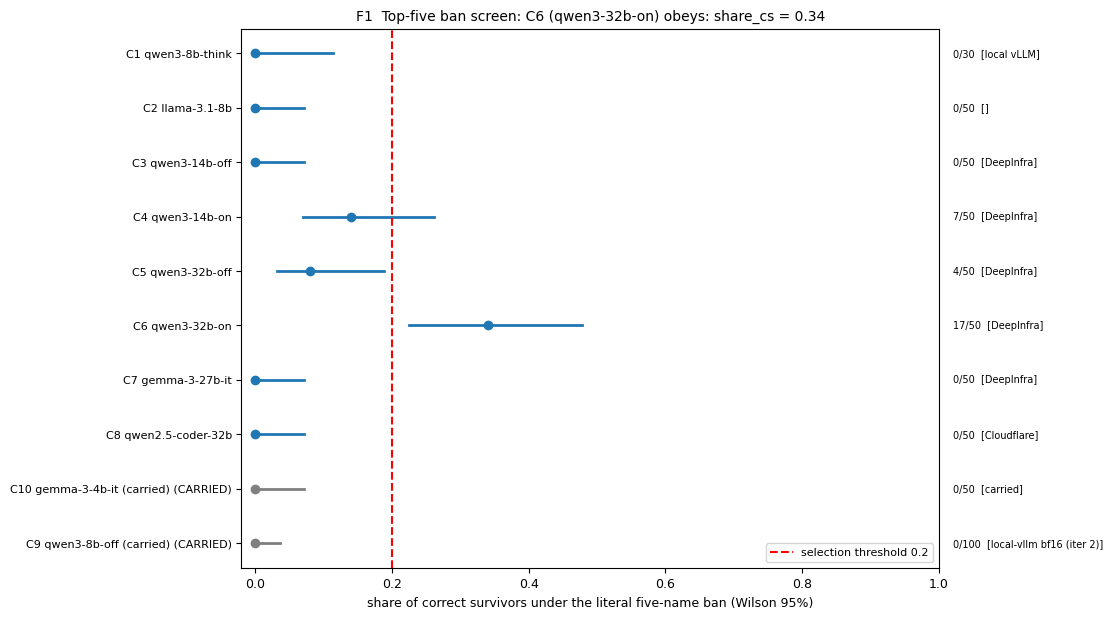

cfg  name                     thinking banned mechanism of which name-free pass rate truncated
C1   qwen3-8b-think           True                 1.00               0.67      0.13      0.20
C2   llama-3.1-8b             False                0.90               0.96      0.02      0.00
C3   qwen3-14b-off            False                1.00               0.94      0.46      0.00
C4   qwen3-14b-on             True                 0.76               0.87      0.32      0.10
C5   qwen3-32b-off            False                0.82               0.68      0.28      0.00
C6   qwen3-32b-on             True                 0.22               0.55      0.42      0.46
C7   gemma-3-27b-it           False                1.00               1.00      0.86      0.00
C8   qwen2.5-coder-32b        False                0.94               0.94      0.40      0.00
C9   qwen3-8b-off (carried)   False                1.00                  -      0.68         -
C10  gemma-3-4b-it (carried)  False               

In [8]:
# ---- from src/screen.py: the committed selection rule (verbatim)
def select(tab: dict[str, Any]) -> dict[str, Any]:
    """Committed rule (new configurations only; carried rows are context)."""
    new = {c: m for c, m in tab.items() if not m.get("carried")}
    q = {c: m for c, m in new.items() if (m["share_cs"] or 0) >= SELECTION["threshold_share_cs"]}
    out: dict[str, Any] = {"Q": sorted(q), "threshold": SELECTION["threshold_share_cs"],
                           "shares": {c: m["share_cs"] for c, m in tab.items()},
                           "upper95_one_sided": {c: m["share_cs_upper95_one_sided"] for c, m in tab.items()}}
    if q:
        best = max(m["share_cs"] for m in q.values())
        tied = [c for c, m in q.items() if best - m["share_cs"] <= SELECTION["tie_window"]]
        tied.sort(key=lambda c: (-q[c]["share_cs_wilson95"][0], q[c]["params_b"], 0 if q[c].get("local") else 1))
        out.update({"m_star": tied[0], "tied": tied, "mode": "SELECTED",
                    "TP_RESULT": f"{tied[0]} ({CONFIGS[tied[0]]['name']}) obeys: share_cs = {q[tied[0]]['share_cs']:.2f}"})
    else:
        most = max(new, key=lambda c: (new[c]["n_correct_survivors"], -new[c]["params_b"]))
        if all(new[c]["n_correct_survivors"] == 0 for c in new):
            most = "C1"
        out.update({"m_star": most, "mode": "DESCRIPTIVE",
                    "TP_RESULT": "no tested open model obeys a five-name ban on this task"})
    return out


# ---- screen_table(): for the new configurations the original builds each row with config_metrics() from
# data/labelled_<cfg>_ban.jsonl (sandboxed hidden tests + adjudicated labels). The demo data carries those rows'
# counts; the share and its Wilson bounds are recomputed exactly as screen_table() does for its carried rows.
tab = {}
for cid, info in md["screen_table"].items():
    n = info["n"]
    k = info.get("n_correct_survivors") or 0
    tab[cid] = {**info, "config": cid, "share_cs": k / n, "share_cs_wilson95": wilson_ci(k, n),
                "share_cs_upper95_one_sided": wilson_upper_one_sided(k, n)}
write_json("screen.json", tab)

# ---- from src/stages.py: stage_select() (commit #3 and its code hashes are not repeated)
sel = select(tab)
for cid, m in sorted(tab.items(), key=lambda kv: kv[0]):
    logger.info(f"{cid:4s} {m['name']:26s} n={m['n']:3d} cs={m['n_correct_survivors']:3d} "
                f"share={m['share_cs']:.3f} CI={[round(x, 3) for x in m['share_cs_wilson95']]} "
                f"comp={m.get('composition')}")
ms = sel["m_star"]
sel["m_star_checkpoint"] = STATE_CHECKPOINTS[ms]
sel["survivor_table"] = {c: m.get("survivor_algorithms") for c, m in tab.items()}
write_json("selection.json", sel)
logger.info(f"SELECTION: {sel['TP_RESULT']} | mode {sel['mode']} | m* = {ms} {STATE_CHECKPOINTS[ms]}")

# ---- from src/stages.py: stage_figures(), F1 (screen forest plot), then how the other configurations disobey
forest(tab, sel)
fmt = lambda v: "-" if v is None else f"{v:.2f}"
print(f"{'cfg':4s} {'name':24s} {'thinking':8s} {'banned mechanism':>16s} {'of which name-free':>18s} "
      f"{'pass rate':>9s} {'truncated':>9s}")
for cid, mt in tab.items():
    print(f"{cid:4s} {mt['name']:24s} {str(mt.get('thinking')):8s} {fmt(mt.get('banned_mechanism_share')):>16s} "
          f"{fmt(mt.get('name_free_reimpl_code')):>18s} {fmt(mt.get('pass_rate')):>9s} "
          f"{fmt(mt.get('truncation_share')):>9s}")
print("C6 correct survivors by algorithm:", tab["C6"]["survivor_algorithms"])

## 4. Geometry code (`src/geometry.py`)

**Layer probe (G2).** For each block, a pipeline of standardise → PCA(64) → multinomial logistic regression predicts which algorithm the prompt forced.
- **Scoring:** balanced accuracy in grouped CV. A group is one (template, alias) paraphrase, held out for all 10 algorithms at once.
- **Choice:** L\* is the best block; ties within 0.01 go to the block nearest depth 0.5.

**Manifold M1 (G3).** At L\*, it computes:
- PCA of the points;
- classical MDS of the points and of the 10 centroids, with Kruskal stress-1;
- Isomap kNN graphs for k = 5, 10, 15, with geodesic distances from shortest paths. Disconnected components are joined by their shortest edges. The primary k is 10 if that graph is connected, otherwise the first connected k.

**Distance to the banned set.** For each non-banned algorithm *a*, `g_k(a)` is the smallest, over banned algorithms *b*, of the mean geodesic distance between the points of *a* and those of *b*.

**Classes**, relative to the median of the five g values:
- **EDGE:** g below the median;
- **MIDDLE:** g at the median;
- **OPPOSITE:** g above the median.

**Reliability:**
- split-half Spearman correlation of the 10×10 class-geodesic matrices (templates 0-4 vs 5-9);
- a bootstrap over paraphrase groups.

The code is copied verbatim; only the number of CV folds reads `N_SPLITS`.

In [9]:
# ---- src/geometry.py (verbatim except that the number of CV folds reads N_SPLITS from the config)
# Stage 7 G2/G3 geometry in actual activation coordinates (no summary bars).
#
# G2 L*: per block, standardise -> PCA(64) fit in fold -> multinomial logistic regression (C=1); grouped 10-fold CV with
# groups = (template t, alias j) pairs (a held-out paraphrase is held out for all 10 algorithms); score = balanced
# accuracy; L* = argmax, ties within 0.01 -> block nearest depth 0.5 (all at ceiling -> nearest depth 0.5 among ceiling).
# G3 M1 at L*: PCA 2D (EVR), classical MDS on the 300 points and the 10 centroids (Kruskal stress-1), Isomap k in
# {5,10,15} on the symmetrised kNN distance graph (shortest inter-component edges added if disconnected, component count
# recorded), geodesics via scipy shortest_path. g_k(a) = min over b in B of mean geodesic distance over pairs (points of
# a, points of b) (iteration-7 top5geo.py definition). Classes: EDGE g < median, MIDDLE g == median, OPPOSITE g > median
# over the 5 non-banned algorithms. Reliability: split-half Spearman of 10x10 mean-geodesic matrices; 1,000 bootstrap
# resamples of paraphrase groups -> class and nearest-banned stability.


# ---------------------------------------------------------------------------------------------- layer selection
def layer_curve(X_blocks: np.ndarray, labels: np.ndarray, groups: np.ndarray, blocks: list[int],
                sel_blocks: list[int], n_layers: int) -> dict[str, Any]:
    from sklearn.decomposition import PCA
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import balanced_accuracy_score
    from sklearn.model_selection import GroupKFold
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    curve = {}
    preds = {}
    gkf = GroupKFold(n_splits=N_SPLITS)                                  # [n_splits=10]
    for b in sel_blocks:
        X = X_blocks[:, blocks.index(b)].astype(np.float64)
        pred = np.empty(len(labels), dtype=object)
        for tr, te in gkf.split(X, labels, groups):
            clf = make_pipeline(StandardScaler(), PCA(n_components=min(64, len(tr) - 1), random_state=0),
                                LogisticRegression(C=1.0, max_iter=3000))
            clf.fit(X[tr], labels[tr])
            pred[te] = clf.predict(X[te])
        curve[b] = float(balanced_accuracy_score(labels, pred.astype(str)))
        preds[b] = [str(x) for x in pred]
    best = max(curve.values())
    near = [b for b in sel_blocks if best - curve[b] <= 0.01]
    L = min(near, key=lambda b: (abs((b + 1) / n_layers - 0.5), b))
    ceiling = [b for b in sel_blocks if curve[b] >= 0.9999]
    rule = "argmax (ties within 0.01 -> nearest depth 0.5)"
    if len(ceiling) == len(sel_blocks):
        L = min(ceiling, key=lambda b: (abs((b + 1) / n_layers - 0.5), b))
        rule = "all blocks at ceiling -> nearest depth 0.5"
    return {"curve": curve, "L_star": int(L), "best": best, "tied_blocks": near, "rule": rule,
            "depth_of_L_star": (L + 1) / n_layers, "cv_pred_at_L": preds[L]}


# ---------------------------------------------------------------------------------------------- graphs
def knn_graph(X: np.ndarray, k: int) -> tuple[csr_matrix, int, int]:
    """Symmetrised kNN distance graph; disconnected components joined by their shortest inter-component edges
    (as sklearn Isomap does). Returns (graph, components before joining, edges added)."""
    D = squareform(pdist(X))
    n = len(X)
    D[D == 0] = 1e-12                       # duplicates (bootstrap) stay connected
    np.fill_diagonal(D, 0.0)
    W = np.zeros((n, n))
    order = np.argsort(D, axis=1)
    for i in range(n):
        nb = [j for j in order[i] if j != i][:k]
        W[i, nb] = D[i, nb]
    W = np.maximum(W, W.T)
    G = csr_matrix(W)
    ncomp, lab = connected_components(G, directed=False)
    added = 0
    if ncomp > 1:
        for a in range(ncomp):
            for b in range(a + 1, ncomp):
                ia, ib = np.where(lab == a)[0], np.where(lab == b)[0]
                sub = D[np.ix_(ia, ib)]
                i, j = np.unravel_index(np.argmin(sub), sub.shape)
                W[ia[i], ib[j]] = W[ib[j], ia[i]] = max(sub[i, j], 1e-12)
                added += 1
        G = csr_matrix(W)
    return G, int(ncomp), added


def geodesics(X: np.ndarray, k: int) -> tuple[np.ndarray, dict[str, Any]]:
    Xu = X.copy()
    # exact duplicates (bootstrap resamples) -> jitter-free handling: dedupe by index mapping
    G, ncomp, added = knn_graph(Xu, k)
    geo = shortest_path(G, method="D", directed=False)
    return geo, {"k": k, "components_before_join": ncomp, "edges_added": added, "connected": ncomp == 1,
                 "finite": bool(np.isfinite(geo).all())}


def class_matrix(geo: np.ndarray, labels: np.ndarray, classes: list[str]) -> np.ndarray:
    M = np.zeros((len(classes), len(classes)))
    for i, a in enumerate(classes):
        for j, b in enumerate(classes):
            sub = geo[np.ix_(labels == a, labels == b)]
            if i == j:
                sub = sub[~np.eye(len(sub), dtype=bool)] if sub.shape[0] == sub.shape[1] else sub
            M[i, j] = float(np.mean(sub)) if sub.size else np.nan
    return M


def g_values(geo: np.ndarray, labels: np.ndarray, banned: list[str], nonbanned: list[str]) -> tuple[dict, dict]:
    g, near = {}, {}
    for a in nonbanned:
        dm = [float(np.mean(geo[np.ix_(labels == a, labels == b)])) for b in banned]
        g[a] = min(dm)
        near[a] = banned[int(np.argmin(dm))]
    return g, near


def g_centroid(X: np.ndarray, labels: np.ndarray, banned: list[str], nonbanned: list[str]) -> tuple[dict, dict]:
    cent = {c: X[labels == c].mean(0) for c in set(labels)}
    g, near = {}, {}
    for a in nonbanned:
        dm = [float(np.linalg.norm(cent[a] - cent[b])) for b in banned]
        g[a] = min(dm)
        near[a] = banned[int(np.argmin(dm))]
    return g, near


def classify(g: dict[str, float]) -> tuple[dict[str, str], float]:
    med = float(np.median(list(g.values())))
    cls = {a: ("EDGE" if v < med - 1e-12 else "OPPOSITE" if v > med + 1e-12 else "MIDDLE") for a, v in g.items()}
    return cls, med


# ---------------------------------------------------------------------------------------------- embeddings
def stress1(D: np.ndarray, Y: np.ndarray) -> float:
    d = squareform(pdist(Y))
    iu = np.triu_indices(len(D), 1)
    return float(np.sqrt(((D[iu] - d[iu]) ** 2).sum() / (D[iu] ** 2).sum()))


def classical_mds(D: np.ndarray, k: int = 2) -> np.ndarray:
    n = len(D)
    J = np.eye(n) - 1.0 / n
    B = -0.5 * J @ (D ** 2) @ J
    w, V = np.linalg.eigh(B)
    i = np.argsort(w)[::-1][:k]
    return V[:, i] * np.sqrt(np.maximum(w[i], 0))


def manifold(X: np.ndarray, labels: np.ndarray, banned: list[str], ks: tuple[int, ...] = (5, 10, 15),
             fit_isomap: bool = True) -> dict[str, Any]:
    """Full M1 description at one block (raw coordinates)."""
    from sklearn.decomposition import PCA
    from sklearn.manifold import Isomap

    nonbanned = [a for a in CANON_ORDER if a not in banned]
    out: dict[str, Any] = {"n_points": int(len(X)), "banned": banned, "nonbanned": nonbanned}
    pca = PCA(n_components=10, random_state=0).fit(X)
    out["pca_evr"] = pca.explained_variance_ratio_[:10].tolist()
    D = squareform(pdist(X))
    Ym = classical_mds(D)
    out["mds_points_stress1"] = stress1(D, Ym)
    cent = np.stack([X[labels == c].mean(0) for c in CANON_ORDER])
    Dc = squareform(pdist(cent))
    Ymc = classical_mds(Dc)
    out["mds_centroids_stress1"] = stress1(Dc, Ymc)
    out["centroid_distance_matrix"] = Dc.tolist()
    emb: dict[str, Any] = {"pca": pca, "mds_points": Ym, "mds_centroids": Ymc, "isomap": {}, "geo": {}}
    for k in ks:
        geo, info = geodesics(X, k)
        g, near = g_values(geo, labels, banned, nonbanned)
        cls, med = classify(g)
        M = class_matrix(geo, labels, CANON_ORDER)
        out[f"k{k}"] = {**info, "g": g, "nearest_banned": near, "classes": cls, "median": med,
                        "class_geodesic_matrix": M.tolist()}
        emb["geo"][k] = geo
        if fit_isomap:
            iso = Isomap(n_neighbors=k, n_components=2)
            Y = iso.fit_transform(X)
            out[f"k{k}"]["isomap_stress1_vs_geodesic"] = stress1(np.where(np.isfinite(geo), geo, np.nanmax(
                geo[np.isfinite(geo)])), Y)
            emb["isomap"][k] = (iso, Y)
    gc_, nc_ = g_centroid(X, labels, banned, nonbanned)
    clc, medc = classify(gc_)
    out["euclid_centroid"] = {"g": gc_, "nearest_banned": nc_, "classes": clc, "median": medc}
    out["k_primary"] = 10 if out["k10"]["connected"] else next((k for k in ks if out[f"k{k}"]["connected"]), 10)
    return out | {"_emb": emb}


def split_half(X: np.ndarray, labels: np.ndarray, groups: np.ndarray, k: int) -> dict[str, Any]:
    h1 = groups < 15
    res = {}
    mats = []
    for m in (h1, ~h1):
        geo, info = geodesics(X[m], k)
        mats.append(class_matrix(geo, labels[m], CANON_ORDER))
    iu = np.triu_indices(10, 1)
    rho = spearmanr(mats[0][iu], mats[1][iu]).statistic
    res["spearman_offdiag"] = float(rho)
    res["k"] = k
    return res


def bootstrap(X: np.ndarray, labels: np.ndarray, groups: np.ndarray, banned: list[str], k: int, n_boot: int = 1000,
              seed: int = 0) -> dict[str, Any]:
    """Resample the 30 paraphrase groups with replacement; duplicates are kept as distinct points (a zero-length edge
    is replaced by 1e-12 so duplicates stay connected)."""
    rng = np.random.default_rng(seed)
    nonbanned = [a for a in CANON_ORDER if a not in banned]
    ug = np.unique(groups)
    full_g, full_near = g_values(geodesics(X, k)[0], labels, banned, nonbanned)
    full_cls, _ = classify(full_g)
    same_cls = {a: 0 for a in nonbanned}
    same_near = {a: 0 for a in nonbanned}
    edge_count = {a: 0 for a in nonbanned}
    for _ in range(n_boot):
        gs = rng.choice(ug, size=len(ug), replace=True)
        idx = np.concatenate([np.where(groups == g)[0] for g in gs])
        Xb = X[idx] + rng.normal(0, 1e-9, size=X[idx].shape)
        geo, _info = geodesics(Xb, k)
        g, near = g_values(geo, labels[idx], banned, nonbanned)
        cls, _ = classify(g)
        for a in nonbanned:
            same_cls[a] += cls[a] == full_cls[a]
            same_near[a] += near[a] == full_near[a]
            edge_count[a] += cls[a] == "EDGE"
    return {"n_boot": n_boot, "k": k, "class_stability": {a: same_cls[a] / n_boot for a in nonbanned},
            "nearest_banned_stability": {a: same_near[a] / n_boot for a in nonbanned},
            "edge_probability": {a: edge_count[a] / n_boot for a in nonbanned}, "full_classes": full_cls,
            "full_nearest": full_near}


def strip_private(d: dict[str, Any]) -> dict[str, Any]:
    return {k: v for k, v in d.items() if not k.startswith("_")}


def synthetic_ring(n_per: int = 30, dim: int = 50, radius: float = 10.0, noise: float = 1.0,
                   seed: int = 0) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """T8: 10 Gaussian clusters on a ring (algorithms in canonical order around the ring)."""
    rng = np.random.default_rng(seed)
    X, lab, grp = [], [], []
    basis = np.linalg.qr(rng.normal(size=(dim, 2)))[0]
    for i, a in enumerate(CANON_ORDER):
        th = 2 * np.pi * i / 10
        c = radius * (np.cos(th) * basis[:, 0] + np.sin(th) * basis[:, 1])
        X.append(c + noise * rng.normal(size=(n_per, dim)) / np.sqrt(dim) * 3)
        lab += [a] * n_per
        grp += list(range(n_per))
    return np.concatenate(X), np.array(lab), np.array(grp)


def log_summary(tag: str, m: dict[str, Any]) -> None:
    kp = m["k_primary"]
    logger.info(f"[{tag}] PCA EVR {np.round(m['pca_evr'][:2], 3).tolist()}, MDS stress1 points "
                f"{m['mds_points_stress1']:.3f} centroids {m['mds_centroids_stress1']:.3f}; k={kp} classes "
                f"{m[f'k{kp}']['classes']} comps {[m[f'k{k}']['components_before_join'] for k in (5, 10, 15)]}")

## 5. Landing-test code (`src/landing.py`)

**The statistic.** S is the mean of g over the algorithms of the correct survivors. A large S means the survivors sit far from the banned set.

**Four nulls.** Each one redraws the survivor labels among the five non-banned algorithms:
- **U:** uniform.
- **F:** by m\*'s baseline frequency, with +0.5 smoothing.
- **P:** the exact 120 permutations of the algorithm identities. This gives an algorithm-level p; with a single landing algorithm its floor is 1/5 = 0.20.
- **C:** by the correct-when-forced rates. This addresses a correctness-filter confound.

**The committed verdict:**
- **EDGE** iff p_edge < 0.05 under both U and F, and more than half of the survivors are in EDGE algorithms.
- **OPPOSITE** is the mirror image.
- **NEITHER** otherwise.

The code is copied verbatim.

In [10]:
# ---- src/landing.py (verbatim)
# Stage 7 G5 landing test. S = mean over correct survivors of g_k(label). Nulls (seed 0):
#   U: labels iid uniform over the 5 non-banned algorithms, 10,000 draws (committed)
#   F: iid by m*'s baseline frequency among non-banned algorithms, +0.5 smoothing, 10,000 draws (committed)
#   P: exact 120 permutations of algorithm identities among the 5, count profile fixed -> algorithm-level p (added)
#   C: iid by correct-when-forced rates, +0.5 smoothed (added; correctness-filter confound)
# p_edge = P(S_null <= S); p_opp = P(S_null >= S).
# VERDICT: EDGE iff p_edge(U) < 0.05 and p_edge(F) < 0.05 and > 50% of survivors in EDGE algorithms; OPPOSITE mirrored;
# else NEITHER. p(P) and p(C) always printed beside it.


def stat(g: dict[str, float], labels: list[str]) -> float:
    return float(np.mean([g[a] for a in labels])) if labels else float("nan")


def iid_null(g: dict[str, float], probs: dict[str, float], n: int, draws: int = 10000, seed: int = 0) -> np.ndarray:
    algs = list(g)
    p = np.array([probs[a] for a in algs], dtype=float)
    p = p / p.sum()
    vals = np.array([g[a] for a in algs])
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(algs), size=(draws, n), p=p)
    return vals[idx].mean(1)


def perm_null(g: dict[str, float], labels: list[str]) -> np.ndarray:
    algs = list(g)
    cnt = collections.Counter(labels)
    counts = np.array([cnt[a] for a in algs], dtype=float)
    vals = np.array([g[a] for a in algs])
    out = []
    for perm in itertools.permutations(range(len(algs))):
        out.append(float((counts * vals[list(perm)]).sum() / counts.sum()))
    return np.array(out)


def pvals(null: np.ndarray, S: float) -> dict[str, float]:
    eps = 1e-12
    return {"p_edge": float(np.mean(null <= S + eps)), "p_opp": float(np.mean(null >= S - eps)),
            "null_mean": float(null.mean()), "null_q": np.quantile(null, [0.025, 0.05, 0.5, 0.95, 0.975]).tolist(),
            "n": int(len(null))}


def landing(g: dict[str, float], classes: dict[str, str], surv: list[str], base_counts: dict[str, int],
            forced_rates: dict[str, float], draws: int = 10000, seed: int = 0) -> dict[str, Any]:
    nonbanned = list(g)
    n = len(surv)
    out: dict[str, Any] = {"n_surv": n, "survivor_counts": dict(collections.Counter(surv)), "g": g, "classes": classes}
    if n == 0:
        out.update({"S": None, "verdict": "NO SURVIVORS", "descriptive_only": True})
        return out
    S = stat(g, surv)
    out["S"] = S
    U = iid_null(g, {a: 1.0 for a in nonbanned}, n, draws, seed)
    fprobs = {a: base_counts.get(a, 0) + 0.5 for a in nonbanned}
    F = iid_null(g, fprobs, n, draws, seed + 1)
    P = perm_null(g, surv)
    cprobs = {a: forced_rates.get(a, 0.0) + 0.5 / 40 for a in nonbanned}
    C = iid_null(g, cprobs, n, draws, seed + 2)
    out["nulls"] = {"U": pvals(U, S), "F": pvals(F, S), "P": pvals(P, S), "C": pvals(C, S)}
    out["null_F_probs"] = fprobs
    out["null_F_near_uniform"] = all(base_counts.get(a, 0) == 0 for a in nonbanned)
    out["null_C_probs"] = cprobs
    share = collections.Counter(classes[a] for a in surv)
    out["class_shares"] = {k: v / n for k, v in share.items()}
    pU, pF = out["nulls"]["U"], out["nulls"]["F"]
    if pU["p_edge"] < 0.05 and pF["p_edge"] < 0.05 and share["EDGE"] / n > 0.5:
        v = "EDGE"
    elif pU["p_opp"] < 0.05 and pF["p_opp"] < 0.05 and share["OPPOSITE"] / n > 0.5:
        v = "OPPOSITE"
    else:
        v = "NEITHER"
    out["verdict"] = v
    out["descriptive_only"] = n < 5
    out["perm_floor"] = float(1.0 / len(P) * sum(1 for x in P if abs(x - P.min()) < 1e-12))
    out["_nulls_raw"] = {"U": U, "F": F, "P": P, "C": C}
    return out


def strip(d: dict[str, Any]) -> dict[str, Any]:
    return {k: v for k, v in d.items() if not k.startswith("_")}

## 6. Load the activation states (replaces `stages._load_smean`)

**What the original reads.** `cache/states/smean_C6_nf4.npz` holds S-mean states for 317 prompts (300 forced, 10 baseline, 3 screen-ban, 4 held-out-ban), at 31 blocks (17-47), in 5120 dimensions. They were extracted from `unsloth/Qwen3-32B-bnb-4bit` with the decoder truncated to 48 of its 64 blocks, which is exact for every block used.

**What `_load_smean` builds instead.** The same dictionary, from the demo data:
- `N_PER_ALGORITHM` forced prompts per algorithm, with templates taken alternately from 0-4 and 5-9 so both split-half halves exist;
- the 17 baseline and ban prompts;
- blocks 29-33 only;
- each state decoded as the block mean plus its float16 residual.

**The other two helpers.** `_mstar` and `_forced_rates` return what the original read from `results/selection.json`, `predictions/commit2.json` and `inputs/exp9/results/catalogue_keep.json`.

In [11]:
# ---- notebook versions of three helpers of src/stages.py that read files of the artifact

def _load_smean(tag: str) -> dict[str, Any]:
    """The demo subset of cache/states/smean_{tag}.npz, decoded from the demo data, with the same keys."""
    assert tag == md["state_tag"], f"the demo data holds the states of {md['state_tag']} only"
    nb, H = len(md["blocks"]), md["hidden_size"]
    mean = np.frombuffer(base64.b64decode(md["block_mean_f32_b64"]), dtype="<f4").reshape(nb, H)

    def state(s: str) -> np.ndarray:            # block mean + float16 residual -> (blocks, hidden) float32
        return mean + np.frombuffer(base64.b64decode(s), dtype="<f2").reshape(nb, H).astype(np.float32)

    # N_PER_ALGORITHM templates per algorithm, taken alternately from the split-half halves (templates 0-4 | 5-9)
    keep_t = [0, 5, 1, 6, 2, 7, 3, 8, 4, 9][:N_PER_ALGORITHM]
    forced = [r for r in rows if r["metadata_template"] in keep_t]
    over = md["overlay_prompts"]
    return {"smean": np.stack([state(r["metadata_state_f16_b64"]) for r in forced]
                              + [state(o["state_f16_b64"]) for o in over]),
            "blocks": np.array(md["blocks"]), "sel_blocks": np.array(PROBE_BLOCKS),
            "kind": np.array(["forced"] * len(forced) + [o["kind"] for o in over]),
            "algorithm": np.array([r["metadata_algorithm"] for r in forced] + [""] * len(over)),
            "group": np.array([r["metadata_group"] for r in forced] + [-1] * len(over)),
            "template": np.array([str(r["metadata_template"]) for r in forced] + [o["template"] for o in over])}


def _mstar() -> tuple[str, dict[str, Any], list[str]]:
    sel = read_json("selection.json")
    ms = sel["m_star"]
    c2 = {"banned_sets": md["banned_sets"]}              # predictions/commit2.json
    return ms, sel, c2["banned_sets"][ms]


def _forced_rates(ms: str) -> tuple[dict[str, float], str]:
    keep = md["catalogue_keep_t1"]                        # inputs/exp9/results/catalogue_keep.json -> ["tasks"]["t1"]
    rates = {a: keep[a]["passed_as_requested"] / keep[a]["n_forced"] for a in CANON_ORDER}
    src = "exp9 catalogue_keep.json passed_as_requested/40 (Qwen3-8B thinking off)"
    if ms not in ("C1",):
        src += " -- TRANSFERRED (G6 not run for this model)"
    return rates, src

## 7. Stage `geometry`, step 1: which block encodes the forced algorithm? (G2)

These are the first lines of `stage_geometry()`. They load m\* and its banned set, then its states, and then run the grouped-CV layer probe on the forced prompts.

**Full run.** Every block from 19 to 45 (depth 0.30-0.70) classified the forced algorithm at balanced accuracy 1.00. The committed ceiling rule therefore takes the block nearest depth 0.5, **L\* = 31** of 64.

**Here.** The probe scores the blocks in `PROBE_BLOCKS`, chosen from the stored blocks 29-33.

In [12]:
# ---- from src/stages.py: stage_geometry(), part 1 ("G2 layer, G3 M1 manifold + reliability, G5 landing +
# robustness + variants, overlays; figures F2/F3/F4/F6"). The module prefixes geometry. / landing. / figures. are
# dropped because those functions are defined in this notebook.
ms, sel, banned = _mstar()
tag = f"{ms}_{STATE_CHECKPOINTS[ms]['precision']}"
z = _load_smean(tag)
blocks = [int(b) for b in z["blocks"]]
sel_b = [int(b) for b in z["sel_blocks"]]
kind = z["kind"]
F = kind == "forced"
Xall = z["smean"].astype(np.float64)
labels = z["algorithm"][F]
groups = z["group"][F].astype(int)
n_layers = md["n_layers"]                     # srec["n_layers"] of results/states_{tag}.json
lc = layer_curve(Xall[F], labels, groups, blocks, sel_b, n_layers)
L = lc["L_star"]
logger.info(f"layer curve {lc['curve']} -> L* = {L} ({lc['rule']})")
print(f"m* = {ms} ({CONFIGS[ms]['name']}), banned set {banned}; states {Xall.shape} = prompts x blocks x dims, "
      f"{int(F.sum())} forced ({ {str(a): c for a, c in collections.Counter(labels).items()} })")


14:46:36|INFO   |layer curve {29: 1.0, 30: 1.0, 31: 1.0, 32: 1.0, 33: 1.0} -> L* = 31 (all blocks at ceiling -> nearest depth 0.5)


m* = C6 (qwen3-32b-on), banned set ['bfs', 'dfs', 'iddfs', 'astar', 'gbfs']; states (117, 5, 5120) = prompts x blocks x dims, 100 forced ({'bfs': 10, 'dfs': 10, 'bibfs': 10, 'iddfs': 10, 'astar': 10, 'gbfs': 10, 'dijkstra_unit': 10, 'idastar': 10, 'jps': 10, 'biastar': 10})


## 8. Step 2: the activation manifold at L* (G3) and its reliability

**The manifold.** `manifold()` describes the forced states at L\* in their raw 5120-d coordinates. It computes PCA, classical MDS and Isomap geodesics for k = 5, 10 and 15, then g and the EDGE / MIDDLE / OPPOSITE class of each non-banned algorithm.

**Full run (300 points):**
- PC1 and PC2 explain 32.4% and 12.0% of the variance.
- The kNN graph has 8, 3 and 1 components at k = 5, 10 and 15, so the primary k is 15.
- Unit Dijkstra is the non-banned algorithm farthest from the banned five (OPPOSITE).
- Bidirectional BFS and bidirectional A\* are EDGE.

**Reliability:**
- the split-half Spearman correlation at each k;
- the bootstrap over paraphrase groups;
- the same manifold on per-dimension standardised coordinates, as a sensitivity check.

In [13]:
# ---- stage_geometry(), part 2: M1 manifold at L*, reliability, standardised-coordinate sensitivity
X = Xall[F][:, blocks.index(L)]
m = manifold(X, labels, banned)
log_summary(tag, m)
kp = m["k_primary"]
rel = {"split_half": {k: split_half(X, labels, groups, k) for k in (5, 10, 15)},
       "bootstrap": bootstrap(X, labels, groups, banned, kp, n_boot=N_BOOT)}                      # [n_boot=1000]
logger.info(f"reliability: split-half {[(k, round(v['spearman_offdiag'], 3)) for k, v in rel['split_half'].items()]}"
            f"; bootstrap class stability {rel['bootstrap']['class_stability']}")
# standardised-coordinate sensitivity
mu, sd = X.mean(0), X.std(0) + 1e-8
m_std = manifold((X - mu) / sd, labels, banned, fit_isomap=False)
print(f"PCA: PC1 {m['pca_evr'][0]:.1%}, PC2 {m['pca_evr'][1]:.1%} of the variance; classical MDS stress-1 "
      f"{m['mds_points_stress1']:.3f} (points), {m['mds_centroids_stress1']:.3f} (centroids); primary k = {kp}")
for k in (5, 10, 15):
    mk = m[f"k{k}"]
    print(f"k={k:2d}: {mk['components_before_join']} kNN component(s); g = "
          + ", ".join(f"{SHORT[a]} {v:.2f}" for a, v in mk["g"].items())
          + "  |  " + ", ".join(f"{SHORT[a]} {c}" for a, c in mk["classes"].items()))

14:46:36|INFO   |[C6_nf4] PCA EVR [0.324, 0.117], MDS stress1 points 0.422 centroids 0.278; k=10 classes {'bibfs': 'EDGE', 'dijkstra_unit': 'OPPOSITE', 'idastar': 'MIDDLE', 'jps': 'OPPOSITE', 'biastar': 'EDGE'} comps [1, 1, 1]


14:46:48|INFO   |reliability: split-half [(5, 0.917), (10, 0.971), (15, 0.966)]; bootstrap class stability {'bibfs': 0.998, 'dijkstra_unit': 0.988, 'idastar': 0.823, 'jps': 0.998, 'biastar': 0.832}


PCA: PC1 32.4%, PC2 11.7% of the variance; classical MDS stress-1 0.422 (points), 0.278 (centroids); primary k = 10
k= 5: 1 kNN component(s); g = BiBFS 12.62, Dijkstra(u) 21.68, IDA* 13.38, JPS 21.61, BiA* 12.13  |  BiBFS EDGE, Dijkstra(u) OPPOSITE, IDA* MIDDLE, JPS OPPOSITE, BiA* EDGE
k=10: 1 kNN component(s); g = BiBFS 9.66, Dijkstra(u) 13.02, IDA* 11.81, JPS 13.86, BiA* 10.67  |  BiBFS EDGE, Dijkstra(u) OPPOSITE, IDA* MIDDLE, JPS OPPOSITE, BiA* EDGE
k=15: 1 kNN component(s); g = BiBFS 8.75, Dijkstra(u) 11.88, IDA* 10.97, JPS 13.14, BiA* 9.47  |  BiBFS EDGE, Dijkstra(u) OPPOSITE, IDA* MIDDLE, JPS OPPOSITE, BiA* EDGE


## 9. Step 3: where do the correct survivors land? (G5) and the robustness grid

**The survivors.** m\*'s 50 screen ban programs contain 17 correct survivors.
- **6 use catalogue algorithms**, all of them unit-weight Dijkstra.
- **The other 11 use known algorithms outside the catalogue**, such as Bellman-Ford/SPFA or a random walk. They have no point on the 10-algorithm manifold, so they are not part of the landing test.

The original derives these labels from `data/labelled_C6_*.jsonl` with `screen.is_correct_survivor()`; the demo data carries the resulting lists.

**Four landing runs.** `landing()` is run once for each of:
- the correct survivors (the primary test);
- every attempted non-banned program;
- Euclidean centroid distances instead of geodesics;
- the standardised coordinates.

**Robustness grid.** The landing is repeated over 5 blocks × 3 k values (L\*-2 … L\*+2 × k = 5, 10, 15). The verdict is **ROBUST** if at least 12 of the 15 cells agree. In the full run 10 of 15 agreed, so it was NOT ROBUST: at k = 5, unit Dijkstra is MIDDLE.

In [14]:
# ---- stage_geometry(), part 3: behaviour of m* -> landing (primary, attempted, Euclidean, standardised), robustness
# The original reads data/labelled_{ms}_baseline.jsonl and data/labelled_{ms}_ban.jsonl here; impl / surv / att are
# the results of its three comprehensions, carried in the demo data:
#   impl = Counter(r["adj_label"] for r in base if r["adj_label"] in CANON_ORDER)
#   surv = [r["adj_label"] for r in ban if screen.is_correct_survivor(r, banned) and r["adj_label"] in nonb]
#   att  = [r["adj_label"] for r in ban if r["adj_label"] in nonb]
beh = md["m_star_behaviour"]
nonb = [a for a in CANON_ORDER if a not in banned]
impl = collections.Counter(beh["baseline_implemented"])
surv = beh["screen_correct_survivors"]
att = beh["screen_attempted_survivors"]
rates, rsrc = _forced_rates(ms)
base_nb = {a: impl.get(a, 0) for a in nonb}
land = landing(m[f"k{kp}"]["g"], m[f"k{kp}"]["classes"], surv, base_nb, rates, draws=N_DRAWS)          # [draws=10000]
land_att = landing(m[f"k{kp}"]["g"], m[f"k{kp}"]["classes"], att, base_nb, rates, draws=N_DRAWS)
land_euc = landing(m["euclid_centroid"]["g"], m["euclid_centroid"]["classes"], surv, base_nb, rates, draws=N_DRAWS)
land_std = landing(m_std[f"k{kp}"]["g"], m_std[f"k{kp}"]["classes"], surv, base_nb, rates, draws=N_DRAWS)
# robustness grid: k x blocks L*-2..L*+2
grid = {}
for b in range(L - 2, L + 3):
    if b not in blocks:
        continue
    mb = m if b == L else manifold(Xall[F][:, blocks.index(b)], labels, banned, fit_isomap=False)
    for k in (5, 10, 15):
        lk = landing(mb[f"k{k}"]["g"], mb[f"k{k}"]["classes"], surv, base_nb, rates, draws=GRID_DRAWS)  # [draws=4000]
        grid[f"L{b}_k{k}"] = {"verdict": lk["verdict"], "classes": mb[f"k{k}"]["classes"],
                              "S": lk.get("S"), "p_edge_U": (lk.get("nulls") or {}).get("U", {}).get("p_edge"),
                              "p_opp_U": (lk.get("nulls") or {}).get("U", {}).get("p_opp"),
                              "components": mb[f"k{k}"]["components_before_join"]}
vc = collections.Counter(v["verdict"] for v in grid.values())
primary = land["verdict"]
rob = {"cells": grid, "verdict_counts": dict(vc), "n_cells": len(grid),
       "identical_to_primary": vc[primary], "ROBUST": vc[primary] >= 12 if len(grid) == 15 else
       vc[primary] >= 0.8 * len(grid)}
print(f"baseline implemented {dict(impl)}; {beh['screen_correct_survivors_incl_other']}/{beh['screen_ban_n']} ban "
      f"programs are correct survivors, catalogue ones: {dict(collections.Counter(surv))}")
for nm, d in (("correct survivors", land), ("attempted", land_att), ("Euclidean centroids", land_euc),
              ("standardised coords", land_std)):
    print(f"{nm:20s} n={d['n_surv']}  S={d['S']:.3f}  verdict={d['verdict']:8s}  p_opp U/F/P/C = "
          + " / ".join(f"{d['nulls'][k]['p_opp']:.4g}" for k in "UFPC"))
print(f"robustness grid: {dict(vc)} -> {rob['identical_to_primary']}/{rob['n_cells']} cells = {primary}, "
      f"ROBUST={rob['ROBUST']}")
for cell, v in grid.items():
    print(f"  {cell:7s} {v['verdict']:8s} unit Dijkstra {v['classes']['dijkstra_unit']:8s} kNN components {v['components']}")

baseline implemented {'bfs': 91}; 17/50 ban programs are correct survivors, catalogue ones: {'dijkstra_unit': 6}
correct survivors    n=6  S=13.024  verdict=OPPOSITE  p_opp U/F/P/C = 0.0221 / 0.0254 / 0.4 / 0.0752
attempted            n=6  S=13.024  verdict=OPPOSITE  p_opp U/F/P/C = 0.0221 / 0.0254 / 0.4 / 0.0752
Euclidean centroids  n=6  S=6.673  verdict=OPPOSITE  p_opp U/F/P/C = 0.0001 / 0.0001 / 0.2 / 0.0566
standardised coords  n=6  S=140.126  verdict=OPPOSITE  p_opp U/F/P/C = 0.0038 / 0.0048 / 0.4 / 0.0744
robustness grid: {'OPPOSITE': 14, 'NEITHER': 1} -> 14/15 cells = OPPOSITE, ROBUST=True
  L29_k5  OPPOSITE unit Dijkstra OPPOSITE kNN components 2
  L29_k10 OPPOSITE unit Dijkstra OPPOSITE kNN components 1
  L29_k15 OPPOSITE unit Dijkstra OPPOSITE kNN components 1
  L30_k5  OPPOSITE unit Dijkstra OPPOSITE kNN components 2
  L30_k10 OPPOSITE unit Dijkstra OPPOSITE kNN components 1
  L30_k15 OPPOSITE unit Dijkstra OPPOSITE kNN components 1
  L31_k5  OPPOSITE unit Dijkstra OPPOSITE 

## 10. Step 4: the geometry in activation coordinates (figures F2, F3, F4, F6)

**Overlays.** The 10 baseline, 3 screen-ban and 4 held-out-ban prompt states are projected onto the fitted PCA and Isomap and drawn over the forced states. They are projected with `transform` only; the fits are never redone.

**Figures:**
- **F2:** PCA.
- **F3:** classical MDS of the points (left) and of the 10 centroids (right).
- **F4:** Isomap at k = 5, 10 and 15. Each panel title gives the classes of the non-banned algorithms, and the overlays are drawn at the primary k.
- **F6:** the landing statistic S (red line) against each null, for the correct survivors and for every attempted non-banned program. The last panel counts the survivors per algorithm, ordered from EDGE to OPPOSITE.

14:46:49|INFO   |LANDING C6: n_surv=6 {'dijkstra_unit': 6} verdict=OPPOSITE attempted n=6 verdict=OPPOSITE; robustness {'OPPOSITE': 14, 'NEITHER': 1}


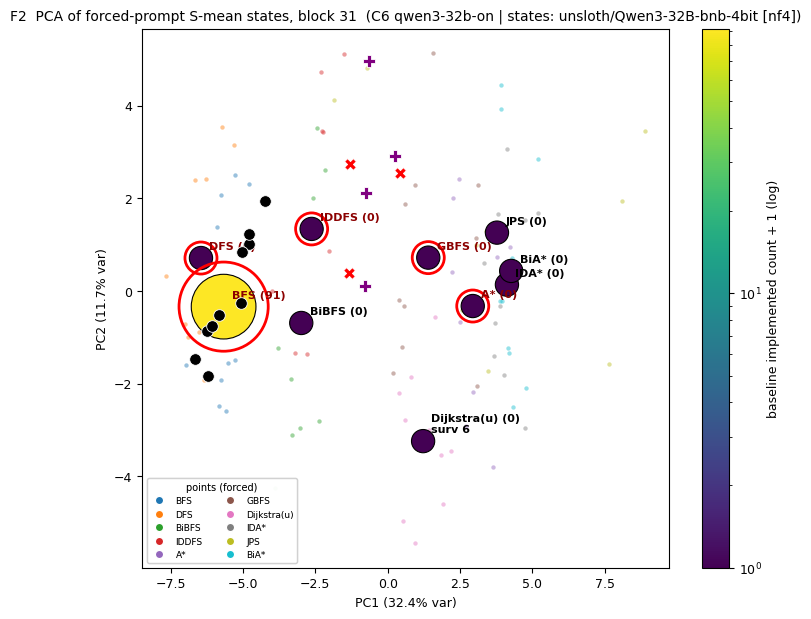

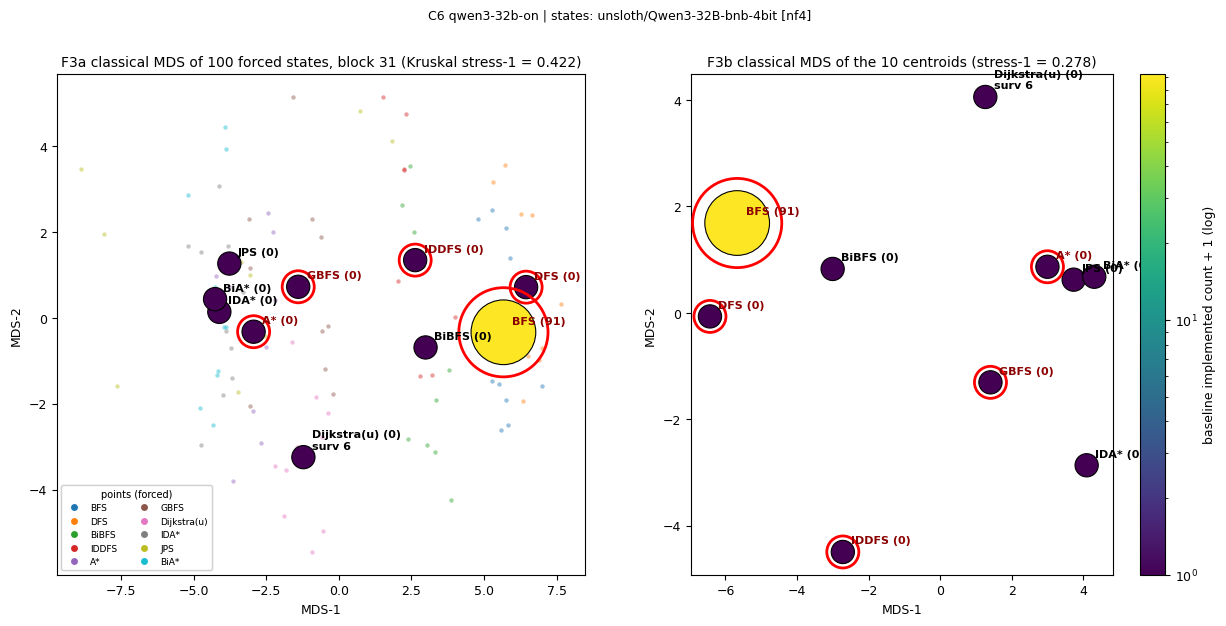

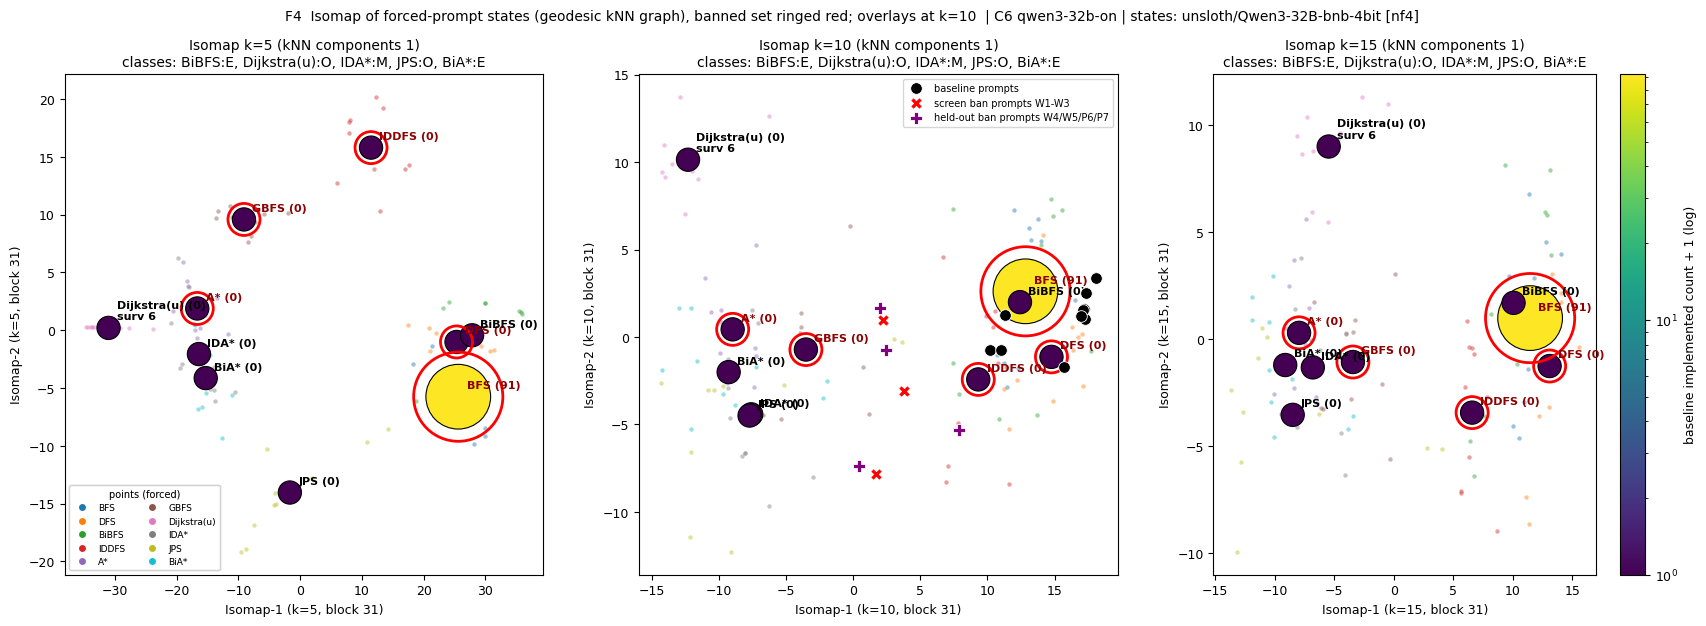

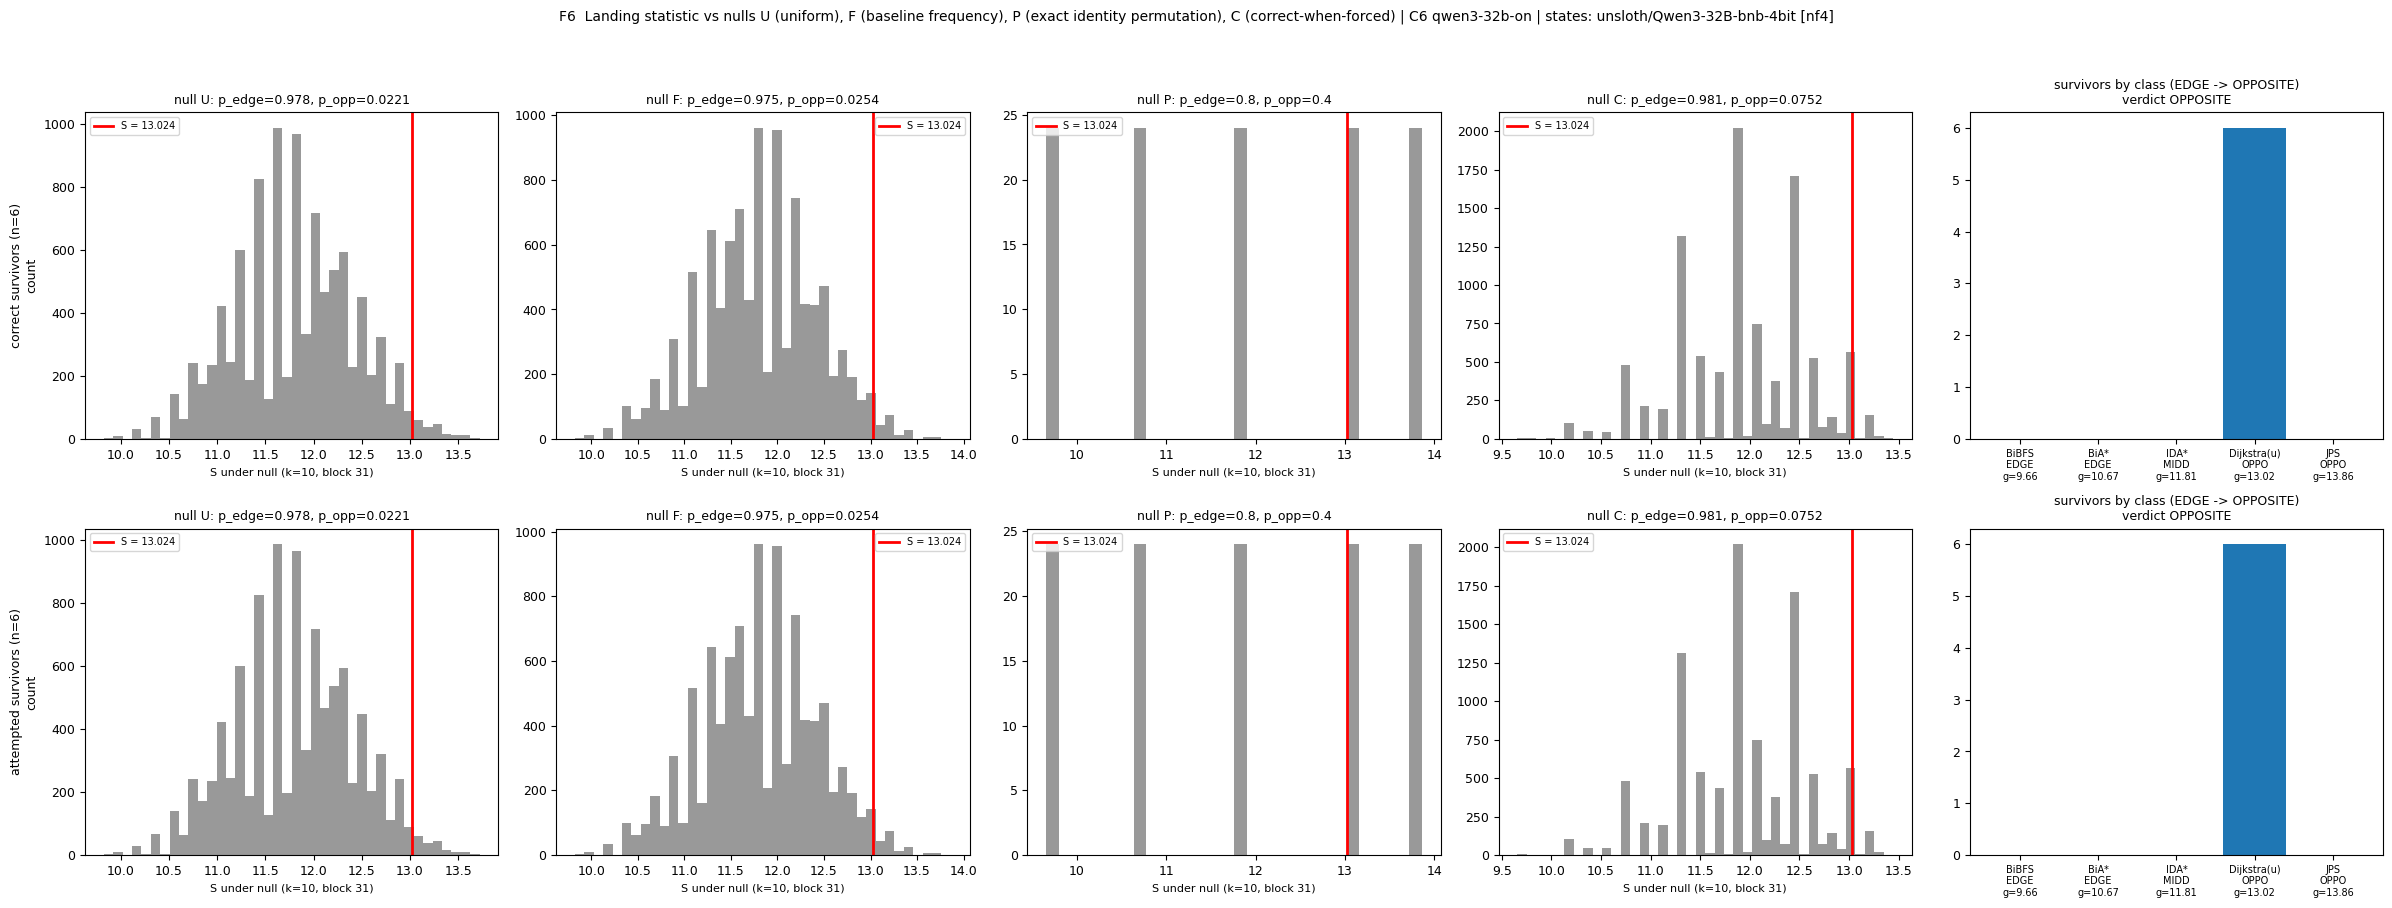

In [15]:
# ---- stage_geometry(), part 4: overlays (transform only, never refit), the results, figures F2/F3/F4/F6
pca = m["_emb"]["pca"]
iso_k, Yk = m["_emb"]["isomap"][kp]
over = {}
for kd in ("baseline", "ban", "confirm"):
    Q = Xall[kind == kd][:, blocks.index(L)]
    over[kd] = {"pca": pca.transform(Q)[:, :2].tolist(), "isomap": iso_k.transform(Q).tolist(),
                "templates": [str(t) for t in z["template"][kind == kd]]}
res = {"config": ms, "tag": tag, "mode": sel["mode"], "banned": banned, "nonbanned": nonb,
       "forced_pca2": [[round(float(a), 4), round(float(b), 4)] for a, b in pca.transform(X)[:, :2]],
       "layer_curve": lc, "L_star": L, "M1": strip_private(m), "M1_standardised":
           strip_private(m_std), "reliability": rel, "overlays": over,
       "baseline_implemented": dict(impl), "engine_tag": f"{ms} states {STATE_CHECKPOINTS[ms]}"}
write_json("geometry_M1.json", res)
lres = {"config": ms, "mode": sel["mode"], "L_star": L, "k": kp, "survivors": surv, "n_surv": len(surv),
        "primary": strip(land), "attempted": strip(land_att),
        "euclid_centroid": strip(land_euc), "standardised": strip(land_std),
        "forced_rates_source": rsrc, "descriptive_only": len(surv) < 5 or sel["mode"] != "SELECTED",
        "note": "correlational description of where behaviour lands; no causal reading (iteration-7 in-manifold "
                "pushes moved 0/300 programs)"}
write_json("landing.json", lres)
write_json("landing_robustness.json", rob)
logger.info(f"LANDING {ms}: n_surv={len(surv)} {dict(collections.Counter(surv))} verdict={land['verdict']} "
            f"attempted n={len(att)} verdict={land_att['verdict']}; robustness {dict(vc)}")
manifold_figures(m, X, labels, banned, impl, over, L, kp, ms, tag, surv, att)
if land.get("_nulls_raw") or land_att.get("_nulls_raw"):
    null_figure(land, land_att, m[f"k{kp}"], ms, L, kp)
# (the original then saved the k = 5/10/15 geodesic matrices to cache/states/geo_{tag}.npz, hashed by commit #4)

## 11. Where do the prompts themselves sit? (stage `refig`)

The landing test asks where the *programs* land. This step asks where the *prompts* put the model. It measures the mean full-dimensional distance from the baseline, screen-ban and held-out-ban prompt states to each of the 10 forced-algorithm centroids at L\*.

In the full run:
- **Baseline prompts** sit nearest DFS and BFS, the algorithms the model writes by default.
- **Ban prompts** move toward IDDFS and greedy best-first. Those are two of the five *named, banned* algorithms, so naming an algorithm primes it.
- **Unit-weight Dijkstra** is the **farthest** centroid from both ban-prompt sets (rank 10 of 10). It is also the only catalogue algorithm the model writes under the ban.

In [16]:
# ---- from src/stages.py: stage_refig(), the full-dimensional placement of the baseline / screen-ban / held-out-ban
# prompt states (mean distance to each forced-algorithm centroid at L*). Its re-render of F2-F4 and F6 is the same as
# above and is not repeated.
geo = read_json("geometry_M1.json")
ms, banned, L = geo["config"], geo["banned"], geo["L_star"]
X = z["smean"][F][:, blocks.index(L)].astype(np.float64)
labels = z["algorithm"][F]
cent = {a: X[labels == a].mean(0) for a in CANON_ORDER}
place = {}
for kd in ("baseline", "ban", "confirm"):
    Q = z["smean"][kind == kd][:, blocks.index(L)].astype(np.float64)
    d = {a: float(np.mean(np.linalg.norm(Q - c, axis=1))) for a, c in cent.items()}
    order = sorted(d, key=d.get)
    place[kd] = {"mean_distance_to_centroid": d, "nearest_order": order,
                 "rank_of_dijkstra_unit": order.index("dijkstra_unit") + 1,
                 "templates": [str(t) for t in z["template"][kind == kd]]}
geo["prompt_state_placement"] = place
write_json("geometry_M1.json", geo)
logger.info(f"placement: { {k: v['nearest_order'][:4] for k, v in place.items()} }")
for kd, p in place.items():
    print(f"{kd:8s} prompts {p['templates']}: nearest centroids {[SHORT[a] for a in p['nearest_order'][:4]]}, "
          f"unit Dijkstra is #{p['rank_of_dijkstra_unit']} of 10")

14:46:51|INFO   |placement: {'baseline': ['dfs', 'bfs', 'bibfs', 'gbfs'], 'ban': ['iddfs', 'gbfs', 'bibfs', 'idastar'], 'confirm': ['gbfs', 'iddfs', 'idastar', 'bibfs']}


baseline prompts ['B0', 'B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B9']: nearest centroids ['DFS', 'BFS', 'BiBFS', 'GBFS'], unit Dijkstra is #7 of 10
ban      prompts ['W1', 'W2', 'W3']: nearest centroids ['IDDFS', 'GBFS', 'BiBFS', 'IDA*'], unit Dijkstra is #10 of 10
confirm  prompts ['W4', 'W5', 'P6', 'P7']: nearest centroids ['GBFS', 'IDDFS', 'IDA*', 'BiBFS'], unit Dijkstra is #10 of 10


## 12. Held-out confirmation on the frozen geometry (stages `confirm` and `figures`)

**What was frozen.** Commit #4 froze L\*, k, the geodesics, g, the classes and the null code before any held-out sample existed.

**The held-out sample.** m\* was then sampled 50 more times with four unseen ban templates: W4 (*"{X} is not allowed here."*), W5, P6 and P7. The programs were labelled and adjudicated as before. 21 of the 50 are correct survivors; 9 of those use catalogue algorithms, all unit Dijkstra.

**The test here.** The 9 catalogue survivors are scored on the frozen g. The result is **CONFIRMED** iff three conditions all hold:
- the verdict equals the screen verdict;
- p < 0.05 under U in that direction;
- a majority of the survivors falls in that class.

**F7** places the held-out ban prompts on the frozen PCA and Isomap axes.

14:46:51|INFO   |CONFIRMATION C6: n_surv 9, verdict OPPOSITE vs screen OPPOSITE -> CONFIRMED=True


held-out arm: 21/50 correct survivors, catalogue ones {'dijkstra_unit': 9}; S = 13.024, p_opp U/F/P/C = 0.0062 / 0.0069 / 0.4 / 0.0228


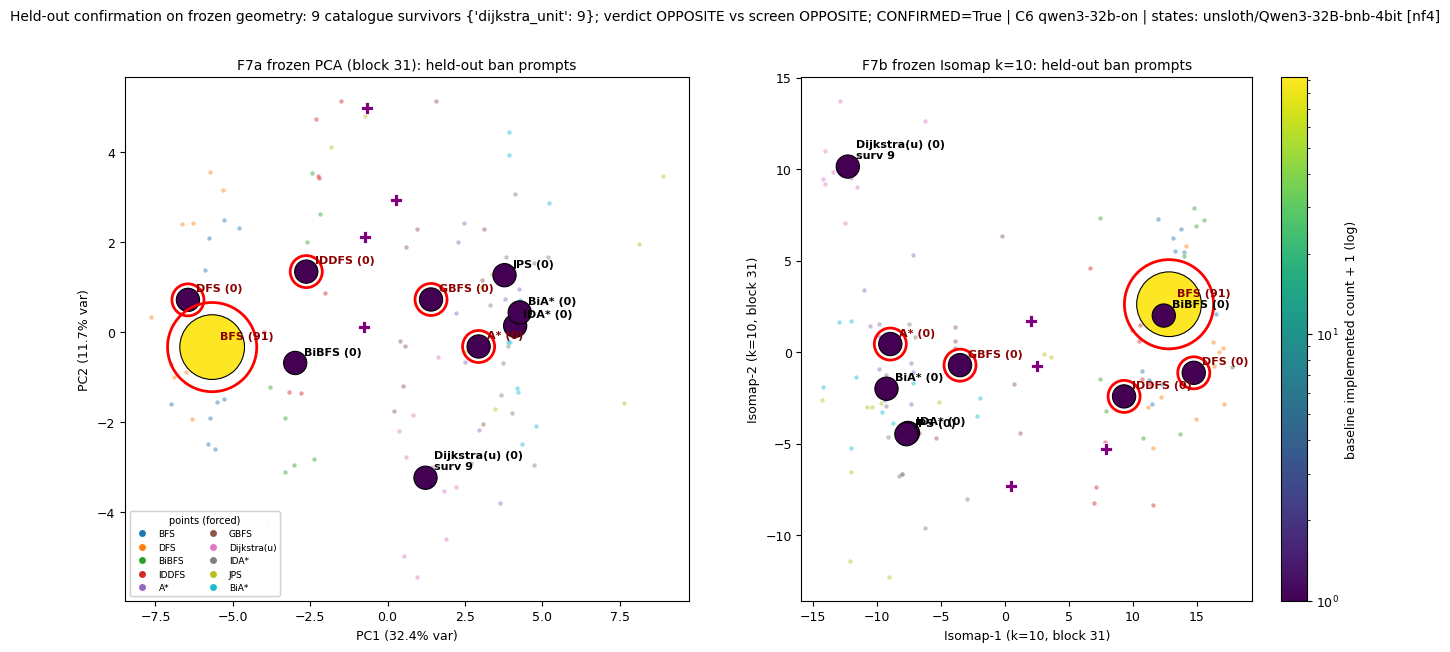

In [17]:
# ---- from src/stages.py: stage_confirm(), from the point where the 50 held-out rows are labelled. Not repeated:
# commit #4 (hashes of the frozen geometry), the OpenRouter sampling with templates W4/W5/P6/P7, labelling and
# adjudication. Their correct catalogue survivors come from the demo data; the original also stored the arm's
# adjudication stats and config_metrics() in the result.
geo = read_json("geometry_M1.json")
land = read_json("landing.json")
kp = geo["M1"]["k_primary"]
tag = geo["tag"]
nonb = [a for a in CANON_ORDER if a not in banned]
surv = beh["confirmation_correct_survivors"]   # [r["adj_label"] for r in rows if screen.is_correct_survivor(r, banned) and r["adj_label"] in nonb]
impl = collections.Counter(beh["baseline_implemented"])
rates, rsrc = _forced_rates(ms)
g = geo["M1"][f"k{kp}"]["g"]
cls = geo["M1"][f"k{kp}"]["classes"]
lc = landing(g, cls, surv, {a: impl.get(a, 0) for a in nonb}, rates, draws=N_DRAWS)
sv = land["primary"]["verdict"]
ok = False
if lc.get("S") is not None and sv in ("EDGE", "OPPOSITE"):
    key = "p_edge" if sv == "EDGE" else "p_opp"
    ok = lc["verdict"] == sv and lc["nulls"]["U"][key] < 0.05 and lc["class_shares"].get(sv, 0) > 0.5
res = {"ran": True, "m_star": ms, "n": beh["confirmation_n"], "survivors": surv, "landing": strip(lc),
       "screen_verdict": sv, "CONFIRMED": ok, "forced_rates_source": rsrc, "engine": STATE_CHECKPOINTS[ms]}
write_json("confirmation.json", res)
logger.info(f"CONFIRMATION {ms}: n_surv {len(surv)}, verdict {lc['verdict']} vs screen {sv} -> CONFIRMED={ok}")
print(f"held-out arm: {beh['confirmation_correct_survivors_incl_other']}/{beh['confirmation_n']} correct survivors, "
      f"catalogue ones {dict(collections.Counter(surv))}; S = {lc['S']:.3f}, p_opp U/F/P/C = "
      + " / ".join(f"{lc['nulls'][k]['p_opp']:.4g}" for k in "UFPC"))

# ---- from src/stages.py: stage_figures(), F7 (held-out ban prompt states placed on the frozen M1 axes)
from sklearn.decomposition import PCA
from sklearn.manifold import Isomap

conf = read_json("confirmation.json")
X = z["smean"][F][:, blocks.index(geo["L_star"])].astype(np.float64)
labels = z["algorithm"][F]
Qc = z["smean"][z["kind"] == "confirm"][:, blocks.index(geo["L_star"])].astype(np.float64)
pca = PCA(n_components=10, random_state=0).fit(X)          # same fit as M1 (deterministic)
iso = Isomap(n_neighbors=kp, n_components=2)
Y = iso.fit_transform(X)
confirmation_figure(geo, X, labels, conf, dict(impl), Y, iso, pca, Qc, geo["config"])

## 13. Is the manifold a circle? (stage `circle`)

**Why ask.** "The opposite side of the banned set" is cleanest on a ring.

**The test.** It compares the largest H1 (loop) persistence from ripser against `N_CIRCLE_NULL` covariance-matched Gaussian clouds, once on each of:
- the forced states (in PCA-20);
- the 10 centroids (in PCA-9).

**Full run.** The points carried some loop signal: 1.59 against a null 95th percentile of 1.29. The centroids carried none: 0.00 against 1.19. EDGE and OPPOSITE are therefore geodesic-distance classes on a non-circular manifold, not positions on a ring.

In [18]:
# ---- from src/stages.py: stage_circle() (verbatim; null count from the config, result kept in RESULTS)
def stage_circle() -> None:
    """G7 (optional): ripser H1 on the 300 M1 points (PCA-20) and on the 10 centroids vs 100 covariance-matched
    Gaussian clouds. Descriptive answer to 'is it a circle'."""
    import numpy as np
    from ripser import ripser
    from sklearn.decomposition import PCA

    geo = read_json("geometry_M1.json")
    z = _load_smean(geo["tag"])
    F = z["kind"] == "forced"
    blocks = [int(b) for b in z["blocks"]]
    X = z["smean"][F][:, blocks.index(geo["L_star"])].astype(np.float64)
    labels = z["algorithm"][F]
    Z = PCA(n_components=20, random_state=0).fit_transform(X)

    def maxp(A: np.ndarray) -> float:
        d = ripser(A, maxdim=1)["dgms"][1]
        return float((d[:, 1] - d[:, 0]).max()) if len(d) else 0.0

    obs = maxp(Z)
    rng = np.random.default_rng(0)
    cov, mu = np.cov(Z.T), Z.mean(0)
    null = [maxp(rng.multivariate_normal(mu, cov, size=len(Z))) for _ in range(N_CIRCLE_NULL)]      # [100]
    C = np.stack([X[labels == a].mean(0) for a in CANON_ORDER])
    Cz = PCA(n_components=9, random_state=0).fit_transform(C)
    obs_c = maxp(Cz)
    covc, muc = np.cov(Cz.T), Cz.mean(0)
    null_c = [maxp(rng.multivariate_normal(muc, covc, size=10)) for _ in range(N_CIRCLE_NULL)]      # [100]
    out = {"points": {"max_H1_persistence": obs, "null_q95": float(np.quantile(null, 0.95)),
                      "p": float(np.mean(np.array(null) >= obs))},
           "centroids": {"max_H1_persistence": obs_c, "null_q95": float(np.quantile(null_c, 0.95)),
                         "p": float(np.mean(np.array(null_c) >= obs_c))},
           "L_star": geo["L_star"], "config": geo["config"]}
    out["is_circle"] = bool(out["points"]["p"] < 0.05 and out["centroids"]["p"] < 0.05)
    write_json("circle_check.json", out)
    logger.info(f"circle check: {out}")


stage_circle()

14:46:52|INFO   |circle check: {'points': {'max_H1_persistence': 1.9699363708496094, 'null_q95': 1.3350770711898803, 'p': 0.0}, 'centroids': {'max_H1_persistence': 0.0, 'null_q95': 0.7840162515640259, 'p': 1.0}, 'L_star': 31, 'config': 'C6', 'is_circle': False}


## 14. Can the method recover planted answers? The synthetic T8 test (stage `t8`)

**Setup.** The test lays out 10 Gaussian clusters on a ring in canonical order. The first five are banned, so the banned set is a contiguous arc whose ring neighbours are positions 5 and 9.

**Checks:**
- **EDGE:** survivors planted next to the arc must give **EDGE**.
- **OPPOSITE:** survivors planted at the far side (position 7) must give **OPPOSITE**.
- **Placebo:** random survivor labels should give a directional verdict only at roughly the nominal rate.
- **Ring:** ripser must recover the ring, i.e. its H1 must exceed that of every Gaussian null cloud.

In the full run every check passed, with a false directional rate of 11%.

In [19]:
# ---- from src/stages.py: stage_t8() (verbatim; loop counts from the config, result kept in RESULTS)
def stage_t8() -> None:
    """T8: geometry + landing on synthetic data (ring of 10 Gaussian clusters, 5 contiguous banned)."""
    import numpy as np

    X, lab, grp = synthetic_ring()
    banned = CANON_ORDER[:5]            # contiguous on the ring: positions 0-4
    nonb = CANON_ORDER[5:]              # 5..9; ring neighbours of the banned arc are positions 5 and 9
    m = manifold(X, lab, banned, fit_isomap=False)
    kp = m["k_primary"]
    g = m[f"k{kp}"]["g"]
    cls = m[f"k{kp}"]["classes"]
    edge_planted = [CANON_ORDER[5]] * 6 + [CANON_ORDER[9]] * 6
    opp_planted = [CANON_ORDER[7]] * 12
    le = landing(g, cls, edge_planted, {a: 0 for a in nonb}, {a: 0.5 for a in nonb})
    lo = landing(g, cls, opp_planted, {a: 0 for a in nonb}, {a: 0.5 for a in nonb})
    rng = np.random.default_rng(1)
    verdicts = []
    for r in range(T8_N_RANDOM):                                  # [200]
        surv = list(rng.choice(nonb, size=12))
        verdicts.append(landing(g, cls, surv, {a: 0 for a in nonb}, {a: 0.5 for a in nonb},
                                draws=2000, seed=r)["verdict"])
    import collections
    vc = collections.Counter(verdicts)
    from ripser import ripser
    from sklearn.decomposition import PCA
    Z = PCA(n_components=20, random_state=0).fit_transform(X)
    dg = ripser(Z, maxdim=1)["dgms"][1]
    maxp = float((dg[:, 1] - dg[:, 0]).max()) if len(dg) else 0.0
    nullp = []
    for s in range(T8_N_NULL):                                    # [20]
        G = np.random.default_rng(100 + s).multivariate_normal(Z.mean(0), np.cov(Z.T), size=len(Z))
        d2 = ripser(G, maxdim=1)["dgms"][1]
        nullp.append(float((d2[:, 1] - d2[:, 0]).max()) if len(d2) else 0.0)
    # (the original divides by its loop count, 200, written as a literal; here T8_N_RANDOM)
    out = {"g": g, "classes": cls, "edge_planted": strip(le), "opp_planted": strip(lo),
           "random_200": dict(vc), "random_false_directional_rate": (vc["EDGE"] + vc["OPPOSITE"]) / T8_N_RANDOM,
           "ripser_ring_maxH1": maxp, "ripser_gauss_null_max": max(nullp),
           "pass": {"edge": le["verdict"] == "EDGE" and le["nulls"]["U"]["p_edge"] < 0.05,
                    "perm_at_floor": le["nulls"]["P"]["p_edge"] <= 0.2 + 1e-9,
                    "opposite": lo["verdict"] == "OPPOSITE",
                    "random_nominal": (vc["EDGE"] + vc["OPPOSITE"]) / T8_N_RANDOM <= 0.12,
                    "ring_recovered": maxp > max(nullp)}}
    write_json("t8_synthetic.json", out)
    logger.info(f"T8: classes {cls}; edge verdict {le['verdict']} pU={le['nulls']['U']['p_edge']:.4f} "
                f"pP={le['nulls']['P']['p_edge']:.3f}; opp verdict {lo['verdict']}; random {dict(vc)}; ripser "
                f"{maxp:.2f} vs null max {max(nullp):.2f}; pass {out['pass']}")


stage_t8()

14:46:53|INFO   |T8: classes {'gbfs': 'EDGE', 'dijkstra_unit': 'MIDDLE', 'idastar': 'OPPOSITE', 'jps': 'OPPOSITE', 'biastar': 'EDGE'}; edge verdict EDGE pU=0.0001 pP=0.100; opp verdict OPPOSITE; random {'NEITHER': 178, 'OPPOSITE': 10, 'EDGE': 12}; ripser 11.58 vs null max 3.40; pass {'edge': True, 'perm_at_floor': True, 'opposite': True, 'random_nominal': True, 'ring_recovered': True}


## 15. Results: this notebook vs the full 300-point run

**The table.** It puts every headline number computed above next to the same number from the full run (`reference_full_run` in the demo data). With 10 instead of 30 points per algorithm, the kNN graphs connect at smaller k, so the primary k and the absolute g values change. Use the table to compare the answers to four questions:
- Is unit Dijkstra OPPOSITE?
- Do the survivors land OPPOSITE?
- Does the verdict survive the robustness grid?
- Where do the ban prompts sit?

**The figure, in activation-derived quantities:**
- **(a)** For each non-banned algorithm, its distance g from the banned five, as a ratio to the median: below 1 is EDGE, above 1 is OPPOSITE. It is shown at each k, for this notebook (filled) and the full run (hollow).
- **(b)** The mean distance from each prompt set's states to each algorithm centroid at L\*.

quantity                                  | this notebook                                           | full run (300 points)
----------------------------------------------------------------------------------------------------------------------------------------
forced prompt states                      | 100 (10 per algorithm)                                  | 300 (30 per algorithm)
selection Q -> m*                         | ['C6'] -> C6                                            | ['C6'] -> C6
layer probe balanced accuracy             | 1.00-1.00 on 5 blocks                                   | 1.00-1.00 on 27 blocks
L*                                        | 31                                                      | 31
PCA variance PC1 / PC2                    | 32.4% / 11.7%                                           | 32.4% / 12.0%
MDS stress-1 points / centroids           | 0.42 / 0.28                                             | 0.42 / 0.28
kNN components k=5/10/15               

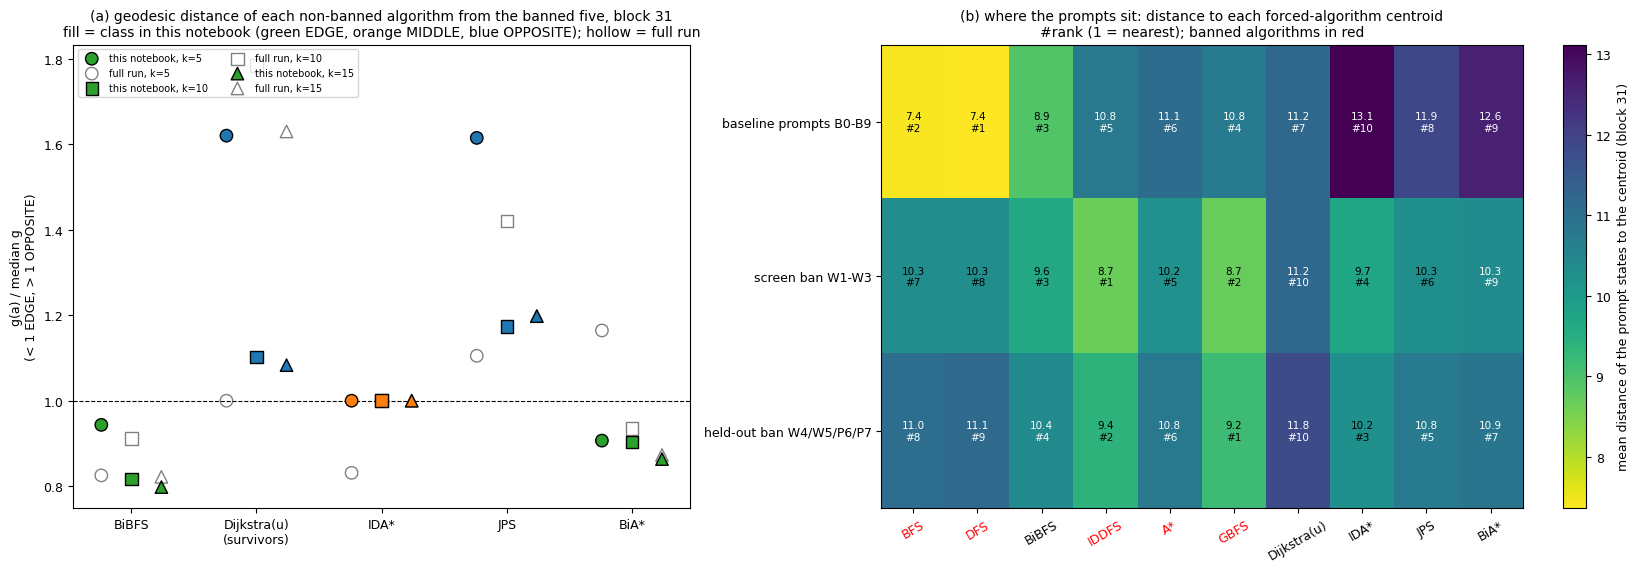

In [20]:
# ---- summary: this notebook's run next to the full 300-point run (reference values from the artifact's results/)
ref = md["reference_full_run"]
geo_r, land_r, rob_r = read_json("geometry_M1.json"), read_json("landing.json"), read_json("landing_robustness.json")
conf_r, circ_r, t8_r, sel_r = (read_json(n) for n in ("confirmation.json", "circle_check.json", "t8_synthetic.json",
                                                       "selection.json"))
M1, lc_r, rel_r, pl = geo_r["M1"], geo_r["layer_curve"], geo_r["reliability"], geo_r["prompt_state_placement"]
kp_r, prim = M1["k_primary"], land_r["primary"]
nb5 = geo_r["nonbanned"]
fmt_cls = lambda c: ", ".join(f"{SHORT[a]}:{v[:3]}" for a, v in c.items())
rank = lambda order: order.index("dijkstra_unit") + 1
summary = [
    ("forced prompt states", f"{M1['n_points']} ({N_PER_ALGORITHM} per algorithm)", f"{ref['n_forced_points']} (30 per algorithm)"),
    ("selection Q -> m*", f"{sel_r['Q']} -> {sel_r['m_star']}", f"{ref['selection_Q']} -> {ref['m_star']}"),
    ("layer probe balanced accuracy", f"{min(lc_r['curve'].values()):.2f}-{max(lc_r['curve'].values()):.2f} on {len(lc_r['curve'])} blocks",
     f"{min(ref['layer_curve'].values()):.2f}-{max(ref['layer_curve'].values()):.2f} on {len(ref['layer_curve'])} blocks"),
    ("L*", geo_r["L_star"], ref["L_star"]),
    ("PCA variance PC1 / PC2", f"{M1['pca_evr'][0]:.1%} / {M1['pca_evr'][1]:.1%}", f"{ref['pca_evr_2'][0]:.1%} / {ref['pca_evr_2'][1]:.1%}"),
    ("MDS stress-1 points / centroids", f"{M1['mds_points_stress1']:.2f} / {M1['mds_centroids_stress1']:.2f}",
     f"{ref['mds_points_stress1']:.2f} / {ref['mds_centroids_stress1']:.2f}"),
    ("kNN components k=5/10/15", "/".join(str(M1[f"k{k}"]["components_before_join"]) for k in (5, 10, 15)),
     "/".join(str(ref["components_before_join"][str(k)]) for k in (5, 10, 15))),
    ("primary k", kp_r, ref["k_primary"]),
    ("classes at the primary k", fmt_cls(M1[f"k{kp_r}"]["classes"]), fmt_cls(ref["classes"][str(ref["k_primary"])])),
    ("unit Dijkstra class at k=5/10/15", "/".join(M1[f"k{k}"]["classes"]["dijkstra_unit"] for k in (5, 10, 15)),
     "/".join(ref["classes"][str(k)]["dijkstra_unit"] for k in (5, 10, 15))),
    ("split-half Spearman k=5/10/15", "/".join(f"{rel_r['split_half'][k]['spearman_offdiag']:.2f}" for k in (5, 10, 15)),
     "/".join(f"{ref['split_half_spearman'][str(k)]:.2f}" for k in (5, 10, 15))),
    ("bootstrap: Dijkstra keeps its class", f"{rel_r['bootstrap']['class_stability']['dijkstra_unit']:.0%} of {N_BOOT}",
     f"{ref['bootstrap_class_stability']['dijkstra_unit']:.0%} of 1000"),
    ("correct catalogue survivors", dict(collections.Counter(land_r["survivors"])), dict(collections.Counter(land_r["survivors"]))),
    ("landing S / verdict", f"{prim['S']:.2f} / {prim['verdict']}", f"{ref['landing_S']:.2f} / {ref['landing_verdict']}"),
    ("p_opp under U / F / P / C", " / ".join(f"{prim['nulls'][k]['p_opp']:.3g}" for k in "UFPC"),
     " / ".join(f"{ref['landing_p_opp'][k]:.3g}" for k in "UFPC")),
    ("robustness grid", f"{rob_r['verdict_counts']} -> ROBUST={rob_r['ROBUST']}",
     f"{ref['robustness_verdict_counts']} -> ROBUST={ref['robustness_ROBUST']}"),
    ("held-out confirmation", f"{conf_r['landing']['verdict']}, CONFIRMED={conf_r['CONFIRMED']}",
     f"{ref['confirmation_verdict']}, CONFIRMED={ref['confirmation_CONFIRMED']}"),
    ("ban prompts: 3 nearest centroids", ", ".join(SHORT[a] for a in pl["ban"]["nearest_order"][:3]),
     ", ".join(SHORT[a] for a in ref["placement_nearest_order"]["ban"][:3])),
    ("Dijkstra rank from ban / held-out prompts", f"{rank(pl['ban']['nearest_order'])} / {rank(pl['confirm']['nearest_order'])} of 10",
     f"{rank(ref['placement_nearest_order']['ban'])} / {rank(ref['placement_nearest_order']['confirm'])} of 10"),
    ("circle check p points / centroids", f"{circ_r['points']['p']:.2f} / {circ_r['centroids']['p']:.2f} -> circle={circ_r['is_circle']}",
     f"{ref['circle_check']['points']['p']:.2f} / {ref['circle_check']['centroids']['p']:.2f} -> circle={ref['circle_check']['is_circle']}"),
    ("T8 synthetic checks passed", f"{sum(t8_r['pass'].values())}/{len(t8_r['pass'])}", f"{sum(ref['t8_pass'].values())}/{len(ref['t8_pass'])}"),
]
w0, w1 = max(len(r[0]) for r in summary), max(len(str(r[1])) for r in summary)
print(f"{'quantity':{w0}s} | {'this notebook':{w1}s} | full run (300 points)")
print("-" * (w0 + w1 + 40))
for name, a, b in summary:
    print(f"{name:{w0}s} | {str(a):{w1}s} | {b}")

# ---- figure: (a) how far each non-banned algorithm is from the banned five, (b) where the prompts themselves sit
fig, axs = plt.subplots(1, 2, figsize=(17, 5.8), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axs[0]
ccol = {"EDGE": "tab:green", "MIDDLE": "tab:orange", "OPPOSITE": "tab:blue"}
for j, k in enumerate((5, 10, 15)):
    gk, ck, med = M1[f"k{k}"]["g"], M1[f"k{k}"]["classes"], M1[f"k{k}"]["median"]
    xs = np.arange(len(nb5)) + (j - 1) * 0.24
    ax.scatter(xs, [gk[a] / med for a in nb5], s=80, c=[ccol[ck[a]] for a in nb5], marker="os^"[j], edgecolor="k",
               zorder=3, label=f"this notebook, k={k}")
    rg = ref["g"][str(k)]
    rmed = float(np.median(list(rg.values())))
    ax.scatter(xs, [rg[a] / rmed for a in nb5], s=80, facecolor="none", edgecolor="grey", marker="os^"[j], zorder=2,
               label=f"full run, k={k}")
ax.axhline(1.0, color="k", lw=0.8, ls="--")
ax.set_xticks(range(len(nb5)))
ax.set_xticklabels([SHORT[a] + ("\n(survivors)" if a in land_r["survivors"] else "") for a in nb5])
ax.set_ylabel("g(a) / median g\n(< 1 EDGE, > 1 OPPOSITE)")
ax.set_title(f"(a) geodesic distance of each non-banned algorithm from the banned five, block {geo_r['L_star']}\n"
             "fill = class in this notebook (green EDGE, orange MIDDLE, blue OPPOSITE); hollow = full run")
ax.legend(fontsize=7, ncol=2, loc="upper left")
ax = axs[1]
kinds = ("baseline", "ban", "confirm")
Dm = np.array([[pl[kd]["mean_distance_to_centroid"][a] for a in CANON_ORDER] for kd in kinds])
im = ax.imshow(Dm, cmap="viridis_r", aspect="auto")
for i, kd in enumerate(kinds):
    order = pl[kd]["nearest_order"]
    for j, a in enumerate(CANON_ORDER):
        ax.text(j, i, f"{Dm[i, j]:.1f}\n#{order.index(a) + 1}", ha="center", va="center", fontsize=7.5,
                color="white" if Dm[i, j] > Dm.mean() else "black")
ax.set_yticks(range(len(kinds)))
ax.set_yticklabels(["baseline prompts B0-B9", "screen ban W1-W3", "held-out ban W4/W5/P6/P7"])
ax.set_xticks(range(len(CANON_ORDER)))
ax.set_xticklabels([SHORT[a] for a in CANON_ORDER], rotation=30)
for t, a in zip(ax.get_xticklabels(), CANON_ORDER):
    t.set_color("red" if a in geo_r["banned"] else "black")
fig.colorbar(im, ax=ax).set_label(f"mean distance of the prompt states to the centroid (block {geo_r['L_star']})")
ax.set_title("(b) where the prompts sit: distance to each forced-algorithm centroid\n"
             "#rank (1 = nearest); banned algorithms in red")
fig.tight_layout()
plt.show()

## What to take away

- **Obeying a ban is rare.** Of 8 open-model configurations, only Qwen3-32B with thinking on writes a correct, non-banned program for at least 20% of the ban prompts (17/50 = 0.34). The same weights without thinking reach 0.08. Models that disobey mostly re-implement BFS or DFS without naming it (55-100% of their banned-mechanism programs are name-free).
- **When it obeys, it lands far from the banned set, not next to it.** Every catalogue survivor is unit-weight Dijkstra: 6 in the screen and 9 on the held-out templates. Unit Dijkstra sits OPPOSITE the banned five on the residual-stream manifold. That holds on the full 300 points and on the 100-point subset here, and it is confirmed on the frozen geometry. The pre-registered EDGE prediction is not supported.
- **The evidence is thin, and the subset shows how fragile the details are.**
  - With a single landing algorithm, the algorithm-level permutation p cannot go below 0.20. It is 0.20 in the full run and 0.40 here, where JPS lies slightly farther than Dijkstra at k = 10.
  - The per-program nulls U and F mostly ask whether that one algorithm has the largest g.
  - The robustness grid depends on how densely the manifold is sampled. With 10 points per algorithm every kNN graph is connected, and 14 of 15 cells say OPPOSITE. In the full run the k = 5 graph splits into 8 components, unit Dijkstra turns MIDDLE, and only 10 of 15 cells agree, so the verdict is NOT ROBUST.
  - The full run's numbers are the result of record.
- **Naming an algorithm primes it.** The ban prompts' own states sit nearest IDDFS and greedy best-first, two of the *named, banned* algorithms. They sit farthest from unit Dijkstra, rank 10 of 10 both here and in the full run, which is the algorithm the model then writes.
- **Not a ring, and correlational only.**
  - The 10 centroids carry no loop (H1 = 0), so EDGE and OPPOSITE are geodesic-distance classes, not positions on a circle.
  - In iteration 7, pushes along this manifold changed 0/300 programs, so nothing here shows that the geometry *causes* the choice.
